# Ablation | RMSIN  ·  ConvNextV2 + HeteroGNN  ·  fp32



---
## 1. Setup & Installation


In [ ]:
!pip install -q einops torchinfo tabulate

In [ ]:
# ============================================================
# 1a. Environment detection & path setup
# ============================================================
import sys, os
from pathlib import Path

IS_COLAB  = 'google.colab' in sys.modules or os.path.exists('/content')
IS_KAGGLE = (not IS_COLAB) and ('KAGGLE_KERNEL_RUN_TYPE' in os.environ
                                or os.path.exists('/kaggle/input'))
IS_LOCAL  = not (IS_KAGGLE or IS_COLAB)

# ────────────────────────────────────────────────────────────
# LOCAL RUN — edit this block to match your machine
# ────────────────────────────────────────────────────────────
# Three ways to point the notebook at your local files:
#   1. Set LOCAL_PROJECT_ROOT below to your project directory
#   2. Set the RMSIN_PROJECT_ROOT environment variable before launching
#      Jupyter (export RMSIN_PROJECT_ROOT=/path/to/project)
#   3. Leave LOCAL_PROJECT_ROOT as None — the notebook will look for
#      ./RMSIN and ./RRSIS-D relative to wherever you started Jupyter
#
# Expected directory layout under LOCAL_PROJECT_ROOT:
#   <root>/
#     ├── rmsin_src/         (the RMSIN repo source)
#     ├── RRSIS-D/           (the dataset, with refs(unc).p, instances.json, JPEGImages/)
#     └── checkpoints/       (auto-created if missing)
#
LOCAL_PROJECT_ROOT = None    # ← set to e.g. r'D:\research\RRSIS-D' on Windows
                              #         or '/home/fahim/research/rrsis' on Linux/macOS
                              #   leave as None to use environment variable or cwd

# ────────────────────────────────────────────────────────────

if IS_KAGGLE:
    RMSIN_REPO_PATH = '/kaggle/input/datasets/fahims45/rmsin-source/rmsin_src'
    DATASET_ROOT    = '/kaggle/input/datasets/fahims45/rrsis-d/RRSIS-D'
    OUTPUT_DIR      = '/kaggle/working'

elif IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)

    RMSIN_REPO_PATH = '/content/drive/MyDrive/CSE465/rmsin_src'
    DATASET_ROOT    = '/content/drive/MyDrive/CSE465/RRSIS-D'
    OUTPUT_DIR      = '/content/drive/MyDrive/CSE465/checkpoints'

else:
    # ── Local run ──
    # Resolution priority: explicit constant → env var → current working dir
    if LOCAL_PROJECT_ROOT is not None:
        root = Path(LOCAL_PROJECT_ROOT).expanduser().resolve()
    elif os.environ.get('RMSIN_PROJECT_ROOT'):
        root = Path(os.environ['RMSIN_PROJECT_ROOT']).expanduser().resolve()
    else:
        root = Path.cwd().resolve()

    RMSIN_REPO_PATH = str(root / 'rmsin_src')
    DATASET_ROOT    = str(root / 'RRSIS-D')
    OUTPUT_DIR      = str(root / 'checkpoints')

# ── Add repo to path & create output dir ──
if RMSIN_REPO_PATH not in sys.path:
    sys.path.insert(0, RMSIN_REPO_PATH)
os.makedirs(OUTPUT_DIR, exist_ok=True)

ENV = 'Kaggle' if IS_KAGGLE else ('Colab' if IS_COLAB else 'Local')
print(f'Environment : {ENV}')
print(f'Repo        : {RMSIN_REPO_PATH}')
print(f'Dataset     : {DATASET_ROOT}')
print(f'Output      : {OUTPUT_DIR}')

# ── Sanity check: warn early if paths are missing ──
missing = []
if not os.path.exists(RMSIN_REPO_PATH):
    missing.append(f'RMSIN repo at {RMSIN_REPO_PATH}')
if not os.path.exists(DATASET_ROOT):
    missing.append(f'Dataset at {DATASET_ROOT}')

if missing:
    print('\n⚠ Path check FAILED — these locations do not exist:')
    for m in missing:
        print(f'    - {m}')
    if IS_LOCAL:
        print('\nFor local runs, fix one of:')
        print('  1. Set LOCAL_PROJECT_ROOT in this cell to your project directory')
        print('  2. Set the RMSIN_PROJECT_ROOT env var, then restart Jupyter')
        print('  3. Launch Jupyter from the directory containing rmsin_src/ and RRSIS-D/')
        print('\nExpected layout:')
        print('  <project_root>/')
        print('    ├── rmsin_src/   (the RMSIN repo)')
        print('    └── RRSIS-D/     (the dataset)')
elif IS_LOCAL:
    print('\n✓ Local paths verified')

Mounted at /content/drive
Environment : Colab
Repo        : /content/drive/MyDrive/CSE465/rmsin_src
Dataset     : /content/drive/MyDrive/CSE465/RRSIS-D
Output      : /content/drive/MyDrive/CSE465/checkpoints


In [ ]:
# ─────────────────────────────────────────────────────────────
# 1b — Core Imports
# ─────────────────────────────────────────────────────────────

import csv
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint as checkpoint_util
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict, OrderedDict
from typing import Optional
from torch import Tensor

import matplotlib.pyplot as plt
from tabulate import tabulate
from torchinfo import summary

import numpy as np
import random
import json
import pickle
import time
import datetime
import gc
import math
import warnings
from pathlib import Path

import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pycocotools import mask as maskUtils
import subprocess, shutil, json
%matplotlib inline

from transformers import ConvNextV2Model, ConvNextV2Config
from transformers import BertModel, BertTokenizer
import timm
from timm.layers import DropPath, to_2tuple, trunc_normal_
from tqdm import tqdm

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')

Device: cuda
GPU: NVIDIA A100-SXM4-40GB
VRAM: 39.5 GB


In [ ]:
# ============================================================
# 1c. Reproductibility
# ============================================================

def seed_everything(seed=2401):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True       # ← fixed input 480x480, safe to enable
    torch.backends.cudnn.deterministic = False   # ← trade exact reproducibility for speed

seed_everything(2401)

In [ ]:
# ============================================================
# 1d. Verify RMSIN repo imports
# ============================================================

repo_ok = True

try:
    from arc import AdaptiveRotatedConv2d, RountingFunction
    print('[OK] arc (AdaptiveRotatedConv2d, RountingFunction)')
except ImportError as e:
    print(f'[FAIL] arc: {e}')
    print('  Fix: ensure arc/__init__.py exports these classes')
    repo_ok = False

try:
    from lib.cross_scale_interaction import CIM
    print('[OK] CIM (Cross-scale Interaction Module)')
except ImportError as e:
    print(f'[FAIL] CIM: {e}')
    repo_ok = False

try:
    from lib.various_receptive import VariousReceptive
    print('[OK] VariousReceptive')
except ImportError as e:
    print(f'[FAIL] VariousReceptive: {e}')
    repo_ok = False

if not repo_ok:
    print('\n*** Some repo imports failed. Check paths and __init__.py files. ***')
else:
    print('\nAll repo imports successful!')


[OK] arc (AdaptiveRotatedConv2d, RountingFunction)
[OK] CIM (Cross-scale Interaction Module)
[OK] VariousReceptive

All repo imports successful!


---
## 2. Configuration


In [ ]:
# ============================================================
# 2a. Config — base hyperparameters
# ============================================================
# Ablation-specific toggles live in the next cell (2b). Keep base
# training hyperparameters here so they're identical across all
# ablation runs.

class Config:
    # ── Paths ──
    dataset_root = DATASET_ROOT
    output_dir   = OUTPUT_DIR
    resume       = ''

    # ── Dataset ──
    dataset  = 'rrsisd'
    splitBy  = 'unc'
    img_size = 480

    # ── Backbone (ConvNeXt-V2 only) ──
    backbone         = 'convnextv2'
    convnextv2_model = 'facebook/convnextv2-base-22k-224'
    layer_decay      = 0.7
    drop_path        = 0.1     # ConvNeXt-V2 Base official
    frozen_stages    = 2

    # ── Text encoder ──
    bert_type     = 'bert-base-uncased'
    bert_lr_scale = 0.1

    # ── Fusion module ──
    fusion_type = 'heterognn'  # 'pwam' | 'heterognn'
    fusion_drop = 0.0
    mha_list    = [1, 1, 1, 1]  # num_heads per stage's fusion module

    # ── Mixed precision (fp32 for this round of ablations) ──
    use_bf16 = True
    use_fp16 = False

    # ── Training ──
    epochs        = 40
    batch_size    = 24         # adjust for fp32 + 480²
    lr            = 3e-5
    weight_decay  = 1e-2
    amsgrad       = False
    loss_weight   = 0.1
    max_tokens    = 20
    max_grad_norm = 1.0
    patience      = 5

    # ── DataLoader ──
    num_workers = 4
    pin_memory  = True

    # ── Logging ──
    print_freq = 10
    model_id   = 'RMSIN_RRSISD_ablation'   # overridden per-ablation in next cell


cfg = Config()
print('=' * 60)
print(' Base Config')
print('=' * 60)
print(f' Backbone   : {cfg.backbone}  ({cfg.convnextv2_model})')
print(f' Fusion     : {cfg.fusion_type}')
print(f' Image size : {cfg.img_size}')
print(f' Batch size : {cfg.batch_size}')
print(f' LR         : {cfg.lr}  (BERT scale: {cfg.bert_lr_scale})')
print(f' Precision  : {cfg.use_bf16}')
print(f' Epochs     : {cfg.epochs}')
print(f' Output dir : {cfg.output_dir}')
print('  → see next cell for ablation flags')

 Base Config
 Backbone   : convnextv2  (facebook/convnextv2-base-22k-224)
 Fusion     : heterognn
 Image size : 480
 Batch size : 24
 LR         : 3e-05  (BERT scale: 0.1)
 Precision  : True
 Epochs     : 40
 Output dir : /content/drive/MyDrive/CSE465/checkpoints
  → see next cell for ablation flags


### 2b. Ablation

In [ ]:
# ============================================================
# 2b. Ablation flags
# ============================================================
# Toggle exactly ONE ablation at a time per run. The model_id is
# auto-derived from the active ablation so checkpoints and logs
# don't collide.
#
# Available ablations:
#   ABLATE_NO_VV         — disable V→V entirely (vv_max_tokens=0)
#   ABLATE_VV_STRIDED    — use strided pooling for V→V at all stages
#                          (full visual features at every stage,
#                           with strided down-sampling for K/V only)
#   ABLATE_ROUNDS_1      — num_rounds = 1
#   ABLATE_ROUNDS_3      — num_rounds = 3
#   (All False) → main HeteroGNN configuration (rounds=2, V→V on
#                  with default token budget, no strided pooling)

# ── Set ONE of these to True per run ──
ABLATE_NO_VV       = False
ABLATE_VV_STRIDED  = False
ABLATE_ROUNDS_1    = False
ABLATE_ROUNDS_3    = False
# (All False = main HeteroGNN)

# ── Derive the actual hyperparameters from flags ──
class AblationCfg:
    """Resolved ablation parameters consumed by HeteroGNN/MMBasicLayer."""
    # HeteroGNN parameters
    gnn_rounds        = 2
    gnn_reverse       = True
    gnn_vv_max_tokens = 4096      # default: V→V active for stages 1–3
    gnn_vv_strided    = False     # NEW: pooled K/V instead of skipping
    gnn_vv_stride     = 4         # pooling stride for V→V K/V

    # Identifier appended to model_id for filename uniqueness
    label = 'main'


# Apply flag(s)
flags_active = sum([ABLATE_NO_VV, ABLATE_VV_STRIDED, ABLATE_ROUNDS_1, ABLATE_ROUNDS_3])
assert flags_active <= 1, 'Only one ablation can be active per run'

if ABLATE_NO_VV:
    AblationCfg.gnn_vv_max_tokens = 0          # never run V→V
    AblationCfg.label = 'no_vv'

elif ABLATE_VV_STRIDED:
    AblationCfg.gnn_vv_strided    = True
    AblationCfg.gnn_vv_max_tokens = 999_999    # always run (pooled) V→V
    AblationCfg.label = 'vv_strided'

elif ABLATE_ROUNDS_1:
    AblationCfg.gnn_rounds = 1
    AblationCfg.label = 'rounds1'

elif ABLATE_ROUNDS_3:
    AblationCfg.gnn_rounds = 3
    AblationCfg.label = 'rounds3'

# Stitch into cfg so downstream cells pick it up unchanged
cfg.gnn_rounds        = AblationCfg.gnn_rounds
cfg.gnn_reverse       = AblationCfg.gnn_reverse
cfg.gnn_vv_max_tokens = AblationCfg.gnn_vv_max_tokens
cfg.gnn_vv_strided    = AblationCfg.gnn_vv_strided
cfg.gnn_vv_stride     = AblationCfg.gnn_vv_stride
cfg.ablation_label    = AblationCfg.label

# Auto-derive model_id so multiple ablations don't overwrite each other's checkpoints
cfg.model_id = f'RMSIN_RRSISD_{cfg.backbone}_{cfg.fusion_type}_{AblationCfg.label}_fp32'

print('=' * 60)
print(' Ablation Configuration')
print('=' * 60)
print(f'  Active ablation : {AblationCfg.label}')
print(f'  num_rounds      : {cfg.gnn_rounds}')
print(f'  use_reverse     : {cfg.gnn_reverse}')
print(f'  vv_max_tokens   : {cfg.gnn_vv_max_tokens}')
print(f'  vv_strided      : {cfg.gnn_vv_strided}'
      + (f'  (stride={cfg.gnn_vv_stride})' if cfg.gnn_vv_strided else ''))
print(f'  model_id        : {cfg.model_id}')
print('=' * 60)

 Ablation Configuration
  Active ablation : main
  num_rounds      : 2
  use_reverse     : True
  vv_max_tokens   : 4096
  vv_strided      : False
  model_id        : RMSIN_RRSISD_convnextv2_heterognn_main_fp32


---
## 3. Data Exploration & Visualization


In [ ]:
# ============================================================
# 3a. Load RRSIS-D metadata
# ============================================================

instances_path = os.path.join(cfg.dataset_root, 'instances.json')
with open(instances_path, 'r') as f:
    instances = json.load(f)

print(f'Images:      {len(instances["images"])}')
print(f'Annotations: {len(instances["annotations"])}')
print(f'Categories:  {len(instances["categories"])}')

# Load referring expressions
refs_path = os.path.join(cfg.dataset_root, f'refs({cfg.splitBy}).p')
with open(refs_path, 'rb') as f:
    all_refs = pickle.load(f)

print(f'Referring expressions: {len(all_refs)}')

split_counts = defaultdict(int)
for ref in all_refs:
    split_counts[ref['split']] += 1
print('Splits:', dict(sorted(split_counts.items())))


Images:      17402
Annotations: 17402
Categories:  20
Referring expressions: 17402
Splits: {'test': 3481, 'train': 12181, 'val': 1740}


In [ ]:
# ============================================================
# 3b. Mask decoding utility
# ============================================================

img_dict = {img['id']: img for img in instances['images']}
ann_dict = {ann['id']: ann for ann in instances['annotations']}

def decode_mask(ann, img_info):
    """Decode COCO-format segmentation into binary mask."""
    seg = ann['segmentation']
    h, w = img_info['height'], img_info['width']

    def _safe_decode(rle, h, w):
        """Decode RLE and force to (h, w) if annotation size mismatches."""
        m = maskUtils.decode(rle)
        if m.shape[:2] != (h, w):
            m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        return m

    if isinstance(seg, dict):
        if isinstance(seg['counts'], list):
            rle = maskUtils.frPyObjects(seg, h, w)
        else:
            rle = seg
        m = _safe_decode(rle, h, w)

    elif isinstance(seg, list):
        if len(seg) > 0 and isinstance(seg[0], dict):
            # List of RLE dicts — decode each and accumulate
            m = np.zeros((h, w), dtype=np.uint8)
            for s in seg:
                m += _safe_decode(s, h, w)          # ← was the crash point
            m = (m > 0).astype(np.uint8)

        elif len(seg) > 0 and isinstance(seg[0], str):
            rle = {'counts': seg[0], 'size': [h, w]}
            m = _safe_decode(rle, h, w)

        else:
            # Polygon format
            rle = maskUtils.frPyObjects(seg, h, w)
            m = maskUtils.decode(rle)
            if m.ndim == 3:
                m = m.sum(axis=2)
            m = (m > 0).astype(np.uint8)
    else:
        m = np.zeros((h, w), dtype=np.uint8)

    if m.ndim == 3:
        m = m.sum(axis=2)
    return (m > 0).astype(np.uint8)

---
## 4. Dataset & Transforms


In [ ]:
# ============================================================
# 4a. Image Transforms (joint image + mask)
# ============================================================

class Compose:
    def __init__(self, transforms):
        self.transforms = transforms
    def __call__(self, image, target):
        for t in self.transforms:
            image, target = t(image, target)
        return image, target

class Resize:
    def __init__(self, h, w):
        self.h, self.w = h, w
    def __call__(self, image, target):
        image = cv2.resize(image, (self.w, self.h), interpolation=cv2.INTER_LINEAR)
        target = cv2.resize(target, (self.w, self.h), interpolation=cv2.INTER_NEAREST)
        return image, target

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p
    def __call__(self, image, target):
        if random.random() < self.p:
            image = np.fliplr(image).copy()
            target = np.fliplr(target).copy()
        return image, target

class ToTensorPair:
    def __call__(self, image, target):
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        target = torch.from_numpy(target).long()
        return image, target

class NormalizePair:
    def __init__(self, mean, std):
        self.mean = torch.tensor(mean).view(3,1,1)
        self.std  = torch.tensor(std).view(3,1,1)
    def __call__(self, image, target):
        return (image - self.mean) / self.std, target

def get_transform(split='train', img_size=480):
    t = [Resize(img_size, img_size)]
    # if split == 'train':
    #     t.append(RandomHorizontalFlip(0.5))
    t += [ToTensorPair(), NormalizePair([0.485,0.456,0.406], [0.229,0.224,0.225])]
    return Compose(t)

print('Transforms defined.')

Transforms defined.


In [ ]:
# ============================================================
# 4b. RRSISDDataset — with HuggingFace BERT tokenizer
# ============================================================

class RRSISDDataset(Dataset):
    """
    RRSIS-D dataset for referring image segmentation.
    Each sample = (image, mask, token_ids, attention_mask).
    Uses HF BERT tokenizer (replaces original custom tokenizer).

    FIXED: Pre-tokenizes ALL sentences once in __init__ instead of
           calling tokenizer per-sample in __getitem__.
    """
    def __init__(self, cfg, split='train', transform=None):
        self.cfg = cfg
        self.split = split
        self.transform = transform
        self.max_tokens = cfg.max_tokens
        self.img_dir = os.path.join(cfg.dataset_root, 'JPEGImages')

        tokenizer = BertTokenizer.from_pretrained(cfg.bert_type)

        # Load metadata
        with open(os.path.join(cfg.dataset_root, 'instances.json')) as f:
            inst = json.load(f)
        self.img_dict = {img['id']: img for img in inst['images']}
        self.ann_dict = {ann['id']: ann for ann in inst['annotations']}

        with open(os.path.join(cfg.dataset_root, f'refs({cfg.splitBy}).p'), 'rb') as f:
            refs = pickle.load(f)

        # Filter by split, flatten (ref, sentence) pairs
        self.samples = []
        for ref in refs:
            if ref['split'] == split:
                for sent in ref['sentences']:
                    self.samples.append({
                        'sent': sent['sent'],
                        'ann_id': ref['ann_id'],
                        'image_id': ref['image_id'],
                    })

        # ── PRE-TOKENIZE all sentences ONCE ────────────────────
        all_sents = [s['sent'] for s in self.samples]
        enc = tokenizer(
            all_sents,
            max_length=self.max_tokens,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        self.all_input_ids  = enc['input_ids']       # (N, max_tokens)
        self.all_attn_masks = enc['attention_mask']   # (N, max_tokens)
        del tokenizer  # free memory — no longer needed
        # ────────────────────────────────────────────────────────

        print(f'[{split}] {len(self.samples)} samples (pre-tokenized)')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img_info = self.img_dict[s['image_id']]
        img = cv2.imread(os.path.join(self.img_dir, img_info['file_name']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = decode_mask(self.ann_dict[s['ann_id']], img_info)

        if self.transform:
          img, mask = self.transform(img, mask)
          mask = mask.long()

        return img, mask, self.all_input_ids[idx], self.all_attn_masks[idx]

In [ ]:
# ============================================================
# 4c. Build DataLoaders
# ============================================================

train_ds = RRSISDDataset(cfg, 'train', get_transform('train', cfg.img_size))
val_ds   = RRSISDDataset(cfg, 'val',   get_transform('val',   cfg.img_size))
test_ds  = RRSISDDataset(cfg, 'test',  get_transform('val',   cfg.img_size))

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=cfg.batch_size, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
test_loader  = DataLoader(test_ds,  batch_size=4, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

print(f'Train: {len(train_loader)} batches (bs={cfg.batch_size})')
print(f'Val:   {len(val_loader)} batches (bs={cfg.batch_size})')
print(f'Test:  {len(test_loader)} batches (bs=4)')


[train] 12181 samples (pre-tokenized)
[val] 1740 samples (pre-tokenized)
[test] 3481 samples (pre-tokenized)
Train: 507 batches (bs=24)
Val:   73 batches (bs=24)
Test:  871 batches (bs=4)


---
## 5. Vision Backbone



In [ ]:
# ============================================================
# 5a. PWAM + HeteroGNN v2 — fusion modules
# ============================================================


# ─── PWAM (original RMSIN fusion) ────────────────────────────
class SpatialImageLanguageAttention(nn.Module):
    def __init__(self, v_in_channels, l_in_channels, key_channels,
                 value_channels, out_channels=None, num_heads=1):
        super().__init__()
        self.v_in_channels = v_in_channels
        self.l_in_channels = l_in_channels
        self.out_channels = out_channels or value_channels
        self.key_channels = key_channels
        self.value_channels = value_channels
        self.num_heads = num_heads

        self.f_key = nn.Sequential(nn.Conv1d(l_in_channels, key_channels, 1, 1))
        self.f_query = nn.Sequential(
            nn.Conv1d(v_in_channels, key_channels, 1, 1),
            nn.InstanceNorm1d(key_channels),
        )
        self.f_value = nn.Sequential(nn.Conv1d(l_in_channels, value_channels, 1, 1))
        self.W = nn.Sequential(
            nn.Conv1d(value_channels, self.out_channels, 1, 1),
            nn.InstanceNorm1d(self.out_channels),
        )

    def forward(self, x, l, l_mask):
        B, HW = x.size(0), x.size(1)
        x_t = x.permute(0, 2, 1)
        l_mask_t = l_mask.permute(0, 2, 1)

        query = self.f_query(x_t).permute(0, 2, 1)
        key = self.f_key(l) * l_mask_t
        value = self.f_value(l) * l_mask_t
        n_l = value.size(-1)

        query = query.reshape(B, HW, self.num_heads,
                              self.key_channels // self.num_heads).permute(0, 2, 1, 3)
        key = key.reshape(B, self.num_heads,
                          self.key_channels // self.num_heads, n_l)
        value = value.reshape(B, self.num_heads,
                              self.value_channels // self.num_heads, n_l)

        sim = torch.matmul(query, key) * (self.key_channels ** -0.5)
        sim = sim + (1e4 * l_mask_t.unsqueeze(1) - 1e4)
        sim = F.softmax(sim, dim=-1)

        out = torch.matmul(sim, value.permute(0, 1, 3, 2))
        out = out.permute(0, 2, 1, 3).contiguous().reshape(B, HW, self.value_channels)
        out = self.W(out.permute(0, 2, 1)).permute(0, 2, 1)
        return out


class PWAM(nn.Module):
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=0, dropout=0.0):
        super().__init__()
        self.vis_project = nn.Sequential(
            nn.Conv1d(dim, dim, 1, 1), nn.GELU(), nn.Dropout(dropout))
        self.image_lang_att = SpatialImageLanguageAttention(
            v_in_channels, l_in_channels, key_channels, value_channels,
            out_channels=value_channels, num_heads=num_heads)
        self.project_mm = nn.Sequential(
            nn.Conv1d(value_channels, value_channels, 1, 1),
            nn.GELU(), nn.Dropout(dropout))

    def forward(self, x, l, l_mask):
        vis = self.vis_project(x.permute(0, 2, 1))
        lang = self.image_lang_att(x, l, l_mask)
        lang = lang.permute(0, 2, 1)
        mm = torch.mul(vis, lang)
        mm = self.project_mm(mm)
        return mm.permute(0, 2, 1)

# ─── HeteroGNN v2 (FIXED ORDERING + CONDITIONAL V→V + OPT. STRIDED V→V) ─
class HeteroGNN(nn.Module):
    """Heterogeneous Graph Neural Network for cross-modal fusion (v2).

    Edge order per round:
        L→L  →  L-FFN  →  L→V  →  V→V  →  V→L  →  V-FFN

    V→V allocation:
      - Disabled (no params) when expected_tokens > vv_max_tokens
      - Skipped entirely when vv_max_tokens == 0
      - Strided variant: full Q at all stages, K/V pooled by stride^2
        (PVT-style spatial reduction). Lets V→V run at stage 0
        without O(N²) cost.
    """
    def __init__(self, dim, v_in_channels, l_in_channels,
                 key_channels, value_channels, num_heads=0, dropout=0.0,
                 num_rounds=2, use_reverse_edges=True,
                 vv_max_tokens=4096, expected_tokens=None,
                 vv_strided=False, vv_stride=4):
        super().__init__()
        self.dim = dim
        self.num_rounds = num_rounds
        self.use_reverse_edges = use_reverse_edges
        self.vv_max_tokens = vv_max_tokens
        self.vv_strided = vv_strided
        self.vv_stride  = vv_stride

        # Decide at construction whether V→V will ever fire.
        # In strided mode the cost is O(N · N/stride²), so even high
        # token counts are affordable.
        if vv_strided:
            self.use_vv = (vv_max_tokens > 0)
        else:
            self.use_vv = (vv_max_tokens > 0) and \
                          ((expected_tokens is None) or (expected_tokens <= vv_max_tokens))
        heads = max(num_heads, 1)

        # Node projections
        self.vis_proj = nn.Sequential(
            nn.Conv1d(v_in_channels, dim, 1), nn.GELU(), nn.Dropout(dropout))
        self.lang_proj = nn.Sequential(
            nn.Conv1d(l_in_channels, dim, 1), nn.GELU(), nn.Dropout(dropout))

        # L→L
        self.ll_attn = nn.ModuleList([
            nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
            for _ in range(num_rounds)])
        self.ll_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        # V→V
        if self.use_vv:
            self.vv_attn = nn.ModuleList([
                nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
                for _ in range(num_rounds)])
            self.vv_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        # V→L
        self.vl_attn = nn.ModuleList([
            nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
            for _ in range(num_rounds)])
        self.vl_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        # L→V
        if use_reverse_edges:
            self.lv_attn = nn.ModuleList([
                nn.MultiheadAttention(dim, heads, batch_first=True, dropout=dropout)
                for _ in range(num_rounds)])
            self.lv_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        # FFNs
        self.v_ffn = nn.ModuleList([
            nn.Sequential(
                nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(dim * 4, dim), nn.Dropout(dropout))
            for _ in range(num_rounds)])
        self.v_ffn_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        self.l_ffn = nn.ModuleList([
            nn.Sequential(
                nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(dropout),
                nn.Linear(dim * 4, dim), nn.Dropout(dropout))
            for _ in range(num_rounds)])
        self.l_ffn_norm = nn.ModuleList([nn.LayerNorm(dim) for _ in range(num_rounds)])

        # Adaptive output gate
        self.output_gate = nn.Sequential(
            nn.Linear(dim, dim), nn.GELU(),
            nn.Linear(dim, dim), nn.Sigmoid())

        # Output projection
        self.out_proj = nn.Sequential(
            nn.Conv1d(dim, dim, 1), nn.GELU(), nn.Dropout(dropout))

    def _pool_kv(self, h_v, HW):
        """Strided pooling for V→V K/V. Q stays at full resolution.
        Returns (B, HW/stride², dim) pooled keys/values."""
        B, _, C = h_v.shape
        h = w = int(math.sqrt(HW))
        assert h * w == HW, f'expected square map, got HW={HW}'
        x_2d   = h_v.transpose(1, 2).reshape(B, C, h, w)
        pooled = F.avg_pool2d(x_2d, kernel_size=self.vv_stride, stride=self.vv_stride)
        return pooled.flatten(2).transpose(1, 2)   # (B, h'·w', C)

    def forward(self, x, l, l_mask):
        v = self.vis_proj(x.permute(0, 2, 1)).permute(0, 2, 1)
        l_nodes = self.lang_proj(l).permute(0, 2, 1)
        lang_kpm = (l_mask.squeeze(-1) == 0) if l_mask is not None else None

        h_v, h_l = v, l_nodes
        HW = h_v.size(1)

        # In non-strided mode, V→V is conditional on token budget
        # In strided mode, V→V always runs (pooling makes it affordable)
        vv_runs_this_stage = self.use_vv and (
            self.vv_strided or HW <= self.vv_max_tokens
        )

        for i in range(self.num_rounds):
            # 1. L→L
            ll_out, _ = self.ll_attn[i](h_l, h_l, h_l, key_padding_mask=lang_kpm)
            h_l = self.ll_norm[i](h_l + ll_out)

            # 2. L-FFN
            h_l = self.l_ffn_norm[i](h_l + self.l_ffn[i](h_l))

            # 3. L→V
            if self.use_reverse_edges:
                lv_out, _ = self.lv_attn[i](h_l, h_v, h_v)
                h_l = self.lv_norm[i](h_l + lv_out)

            # 4. V→V
            if vv_runs_this_stage:
                if self.vv_strided:
                    kv = self._pool_kv(h_v, HW)            # pooled K/V
                    vv_out, _ = self.vv_attn[i](h_v, kv, kv)   # full Q
                else:
                    vv_out, _ = self.vv_attn[i](h_v, h_v, h_v)
                h_v = self.vv_norm[i](h_v + vv_out)

            # 5. V→L
            vl_out, _ = self.vl_attn[i](h_v, h_l, h_l, key_padding_mask=lang_kpm)
            h_v = self.vl_norm[i](h_v + vl_out)

            # 6. V-FFN
            h_v = self.v_ffn_norm[i](h_v + self.v_ffn[i](h_v))

        # Output gating
        gate = self.output_gate(h_v)
        blended = gate * h_v + (1 - gate) * v
        out = self.out_proj(blended.permute(0, 2, 1)).permute(0, 2, 1)
        return out


print('PWAM and HeteroGNN v2 fusion modules defined.')
print(f'  Selection: cfg.fusion_type = {getattr(cfg, "fusion_type", "pwam")}')

PWAM and HeteroGNN v2 fusion modules defined.
  Selection: cfg.fusion_type = heterognn


In [ ]:
# ============================================================
# 5b. MultiModalConvNeXtV2 — ConvNeXt-V2 backbone with cross-modal fusion
# ============================================================

class MMConvNeXtV2Stage(nn.Module):
    """One stage of MultiModal ConvNeXt-V2.

    Per-stage flow:
        ConvNeXt-V2 blocks → flatten → (PWAM | HeteroGNN) fusion
                          → gated sum (res_gate, visual_gate)
                          → reshape back to (B, C, H, W)

    Returns the un-gated fusion output `x_residual` for the decoder skip
    connection, and the gated output `x_out` for the next stage. This
    matches the original RMSIN MMBasicLayer convention.
    """
    def __init__(self, convnext_blocks, dim, stage_idx,
                 num_heads_fusion=1, fusion_drop=0.0,
                 use_checkpoint=False):
        super().__init__()
        self.blocks = convnext_blocks
        self.dim = dim
        self.stage_idx = stage_idx
        self.use_checkpoint = use_checkpoint

        # ── Compute expected token count for this stage ──
        # ConvNeXt-V2: stem (4× downsample) + 2× per stage transition.
        # Stage k:  spatial = img_size / 4 / 2^k   →   tokens = spatial^2
        spatial = cfg.img_size // 4 // (2 ** stage_idx)
        expected_tokens = spatial * spatial
        vv_max = getattr(cfg, 'gnn_vv_max_tokens', 4096)

        # ── Cross-modal fusion module ──
        if getattr(cfg, 'fusion_type', 'pwam') == 'heterognn':
            self.fusion = HeteroGNN(
                dim, dim, 768, dim, dim,
                num_heads=num_heads_fusion, dropout=fusion_drop,
                num_rounds=getattr(cfg, 'gnn_rounds', 2),
                use_reverse_edges=getattr(cfg, 'gnn_reverse', True),
                vv_max_tokens=vv_max,
                expected_tokens=expected_tokens,
                vv_strided=getattr(cfg, 'gnn_vv_strided', False),
                vv_stride=getattr(cfg, 'gnn_vv_stride', 4),
            )
            vv_status = 'on' if self.fusion.use_vv else 'OFF'
            mode = ' (strided)' if (getattr(cfg, 'gnn_vv_strided', False)
                                     and self.fusion.use_vv) else ''
            print(f'  stage{stage_idx} (dim={dim}, tokens={expected_tokens:>5}): '
                  f'V→V {vv_status}{mode}')
        else:
            self.fusion = PWAM(
                dim, dim, 768, dim, dim,
                num_heads=num_heads_fusion, dropout=fusion_drop,
            )

        # ── Gating (same as RMSIN MMBasicLayer) ──
        self.res_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )
        self.visual_residual = VariousReceptive(dim)
        self.visual_gate = nn.Sequential(
            nn.Linear(dim, dim, bias=False), nn.ReLU(),
            nn.Linear(dim, dim, bias=False), nn.Tanh(),
        )

    def forward(self, x, l, l_mask):
        """
        Args:
            x:      (B, C, H, W)   visual features (channels-first)
            l:      (B, 768, N_l)  language features
            l_mask: (B, N_l, 1)    language mask
        Returns:
            x_residual: (B, H*W, C)  fusion-only output (for decoder skip)
            H, W:       int          spatial dims after this stage
            x_out:      (B, C, H, W) gated output (feeds next stage)
        """
        # ── ConvNeXt-V2 blocks ──
        for blk in self.blocks:
            if self.use_checkpoint:
                x = checkpoint_util.checkpoint(blk, x, use_reentrant=False)
            else:
                x = blk(x)

        B, C, H, W = x.shape
        x_flat = x.flatten(2).transpose(1, 2)             # (B, H*W, C)

        # ── Cross-modal fusion + gated residual ──
        v_residual = self.visual_residual(x_flat)
        x_residual = self.fusion(x_flat, l, l_mask)        # (B, H*W, C)

        x_fused = x_flat + (self.res_gate(x_residual) * x_residual) + \
                           (self.visual_gate(v_residual) * v_residual)

        x_out = x_fused.transpose(1, 2).view(B, C, H, W)
        return x_residual, H, W, x_out


class MultiModalConvNeXtV2(nn.Module):
    """ConvNeXt-V2 backbone with per-stage cross-modal fusion + CIM.

    Architecture:
        Image → Stem(4×↓) → [Stage0 → Stage1 → Stage2 → Stage3] → CIM
        Each stage: [Downsample] → ConvNeXt blocks → fusion → gating

    Channel dims for Base: [128, 256, 512, 1024] — identical to Swin-Base,
    so SimpleDecoding and CIM remain unchanged downstream.

    Same forward signature as the previous Swin backbone:
        backbone(image, l_feats, l_mask) → tuple of 4 multi-scale features
    """
    def __init__(self, pretrained_model_name='facebook/convnextv2-base-22k-224',
                 out_indices=(0, 1, 2, 3),
                 use_checkpoint=False,
                 num_heads_fusion=[1, 1, 1, 1],
                 fusion_drop=0.0,
                 drop_path=0.1,
                 frozen_stages=-1):
        super().__init__()
        self.out_indices = out_indices
        self.frozen_stages = frozen_stages

        # ── Load pretrained ConvNeXt-V2 with drop_path override ──
        print(f'Loading ConvNeXt-V2 from: {pretrained_model_name}')
        hf_config = ConvNextV2Config.from_pretrained(pretrained_model_name)
        hf_config.drop_path_rate = drop_path
        convnext = ConvNextV2Model.from_pretrained(
            pretrained_model_name, config=hf_config)
        self.hidden_sizes = hf_config.hidden_sizes        # [128, 256, 512, 1024]
        self.num_features = self.hidden_sizes              # alias for compatibility

        # Stem (Conv2d k=4 s=4 + LayerNorm)
        self.stem = convnext.embeddings

        # Decompose each HF stage into downsampling + blocks + fusion
        self.downsample_layers = nn.ModuleList()
        self.mm_stages = nn.ModuleList()

        for i, hf_stage in enumerate(convnext.encoder.stages):
            # Downsampling layer (Identity for stage 0, LN + Conv2d↓2 for 1-3)
            if len(hf_stage.downsampling_layer) > 0:
                self.downsample_layers.append(
                    nn.Sequential(*list(hf_stage.downsampling_layer)))
            else:
                self.downsample_layers.append(nn.Identity())

            # ConvNeXt blocks + cross-modal fusion
            self.mm_stages.append(MMConvNeXtV2Stage(
                convnext_blocks=hf_stage.layers,
                dim=self.hidden_sizes[i],
                stage_idx=i,
                num_heads_fusion=num_heads_fusion[i],
                fusion_drop=fusion_drop,
                use_checkpoint=use_checkpoint and (i == 2),
            ))

        # Per-stage output normalisation (matches RMSIN's norm{i} pattern)
        for i in out_indices:
            self.add_module(f'norm{i}', nn.LayerNorm(self.hidden_sizes[i]))

        # Cross-Scale Interaction Module
        self.cim = CIM(dim=sum(self.hidden_sizes))

        del convnext   # free temporary HF model after extracting submodules

        # ── Freeze stages if requested ──
        self._freeze_stages()

        # ── Build-time report ──
        frozen_params = sum(p.numel() for p in self.parameters() if not p.requires_grad)
        total_params  = sum(p.numel() for p in self.parameters())
        print(f'  Channels   : {self.hidden_sizes}')
        print(f'  Depths     : {list(hf_config.depths)}')
        print(f'  drop_path  : {drop_path}')
        print(f'  frozen_stg : {frozen_stages}')
        print(f'  Frozen     : {frozen_params:,} / {total_params:,} backbone params '
              f'({100*frozen_params/total_params:.1f}%)')

    def _freeze_stages(self):
        """Freeze stem and early ConvNeXt blocks (NOT fusion modules).

        frozen_stages=-1: nothing frozen
        frozen_stages= 0: stem frozen
        frozen_stages= k: stem + stages 0..k-1 (blocks + downsample) frozen

        Fusion modules (PWAM/HeteroGNN), VariousReceptive, gates, norms,
        and CIM always train regardless of frozen_stages.
        """
        if self.frozen_stages >= 0:
            self.stem.eval()
            for p in self.stem.parameters():
                p.requires_grad = False

        for i in range(min(self.frozen_stages + 1, len(self.mm_stages))):
            # Downsample layer
            self.downsample_layers[i].eval()
            for p in self.downsample_layers[i].parameters():
                p.requires_grad = False

            # ConvNeXt blocks only — fusion stays trainable
            for p in self.mm_stages[i].blocks.parameters():
                p.requires_grad = False

    def forward(self, x, l, l_mask):
        """
        Args:
            x:      (B, 3, H, W)   image
            l:      (B, 768, N_l)  language features (channel-first)
            l_mask: (B, N_l, 1)    language attention mask
        Returns:
            tuple of 4 multi-scale feature maps after CIM, each (B, C_i, H_i, W_i)
        """
        x = self.stem(x)                                  # (B, 128, H/4, W/4)

        outs = []
        for i in range(len(self.mm_stages)):
            x = self.downsample_layers[i](x)
            x_residual, H, W, x = self.mm_stages[i](x, l, l_mask)

            if i in self.out_indices:
                norm_layer = getattr(self, f'norm{i}')
                x_out = norm_layer(x_residual)
                out = x_out.view(-1, H, W, self.hidden_sizes[i]) \
                           .permute(0, 3, 1, 2).contiguous()
                outs.append(out)

        outs = self.cim(outs)
        return tuple(outs)

    def train(self, mode=True):
        """Override to keep frozen stages in eval mode."""
        super().train(mode)
        self._freeze_stages()
        return self


print('MultiModalConvNeXtV2 defined.')
print('  → forward(image, l_feats, l_mask) → tuple of 4 multi-scale features')
print('  → channels [128, 256, 512, 1024]; downstream decoder/CIM unchanged')
print('  → V→V flags plumbed: cfg.gnn_vv_max_tokens, cfg.gnn_vv_strided, cfg.gnn_vv_stride')

MultiModalConvNeXtV2 defined.
  → forward(image, l_feats, l_mask) → tuple of 4 multi-scale features
  → channels [128, 256, 512, 1024]; downstream decoder/CIM unchanged
  → V→V flags plumbed: cfg.gnn_vv_max_tokens, cfg.gnn_vv_strided, cfg.gnn_vv_stride


---
## 6. Decoder — SimpleDecoding


In [ ]:
# ============================================================
# 6. SimpleDecoding with optional Adaptive Rotated Conv
# ============================================================

def make_arc_or_conv(in_ch, out_ch, ks=3, pad=1, bias=False):
    """Use ARC if available, else standard Conv2d."""
    try:
        rf = RountingFunction(in_channels=in_ch, kernel_number=1)
        return AdaptiveRotatedConv2d(
            in_channels=in_ch, out_channels=out_ch,
            kernel_size=ks, padding=pad,
            rounting_func=rf, bias=bias, kernel_number=1)
    except Exception:
        return nn.Conv2d(in_ch, out_ch, ks, padding=pad, bias=bias)


class SimpleDecoding(nn.Module):
    """FPN-style top-down decoder with ARC."""
    def __init__(self, c4_dims, factor=2):
        super().__init__()
        h = c4_dims // factor
        c3 = c4_dims // (factor**1)
        c2 = c4_dims // (factor**2)
        c1 = c4_dims // (factor**3)

        # Stage 4+3
        self.conv1_4 = nn.Conv2d(c4_dims + c3, h, 3, padding=1, bias=False)
        self.conv2_4 = make_arc_or_conv(h, h)
        self.bn1_4, self.bn2_4 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_4, self.relu2_4 = nn.ReLU(), nn.ReLU()
        # Stage +2
        self.conv1_3 = nn.Conv2d(h + c2, h, 3, padding=1, bias=False)
        self.conv2_3 = make_arc_or_conv(h, h)
        self.bn1_3, self.bn2_3 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_3, self.relu2_3 = nn.ReLU(), nn.ReLU()
        # Stage +1
        self.conv1_2 = nn.Conv2d(h + c1, h, 3, padding=1, bias=False)
        self.conv2_2 = make_arc_or_conv(h, h)
        self.bn1_2, self.bn2_2 = nn.BatchNorm2d(h), nn.BatchNorm2d(h)
        self.relu1_2, self.relu2_2 = nn.ReLU(), nn.ReLU()
        # Head
        self.head = nn.Conv2d(h, 2, 1)

    def forward(self, x_c4, x_c3, x_c2, x_c1):
        if x_c4.size(-2) < x_c3.size(-2) or x_c4.size(-1) < x_c3.size(-1):
            x_c4 = F.interpolate(x_c4, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_4(self.bn1_4(self.conv1_4(torch.cat([x_c4, x_c3], 1))))
        x = self.relu2_4(self.bn2_4(self.conv2_4(x)))

        if x.size(-2) < x_c2.size(-2) or x.size(-1) < x_c2.size(-1):
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_3(self.bn1_3(self.conv1_3(torch.cat([x, x_c2], 1))))
        x = self.relu2_3(self.bn2_3(self.conv2_3(x)))

        if x.size(-2) < x_c1.size(-2) or x.size(-1) < x_c1.size(-1):
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=True)
        x = self.relu1_2(self.bn1_2(self.conv1_2(torch.cat([x, x_c1], 1))))
        x = self.relu2_2(self.bn2_2(self.conv2_2(x)))

        return self.head(x)

print('SimpleDecoding defined.')


SimpleDecoding defined.


---
## 7. Model Assembly


In [ ]:
# ============================================================
# 7a. RMSINModel — full model with HF BERT
# ============================================================

class RMSINModel(nn.Module):
    def __init__(self, backbone, classifier, cfg):
        super().__init__()
        self.backbone = backbone
        self.classifier = classifier
        self.text_encoder = BertModel.from_pretrained(cfg.bert_type)
        self.text_encoder.pooler = None

    def forward(self, image, sentences, attentions):
        """
        image:      (B, 3, H, W)
        sentences:  (B, N_l) token IDs
        attentions: (B, N_l) attention mask
        """
        # Text encoding
        bert_out = self.text_encoder(input_ids=sentences, attention_mask=attentions)
        l_feats = bert_out.last_hidden_state.permute(0, 2, 1)  # (B, 768, N_l)
        l_mask  = attentions.unsqueeze(-1).float()              # (B, N_l, 1)

        # Vision backbone with cross-modal fusion
        features = self.backbone(image, l_feats, l_mask)

        # Decode
        x_c1, x_c2, x_c3, x_c4 = features
        return self.classifier(x_c4, x_c3, x_c2, x_c1)

print('RMSINModel defined.')


RMSINModel defined.


In [ ]:
# ============================================================
# 7b. Build & load pretrained weights (ConvNeXt-V2)
# ============================================================

def build_model(cfg):
    convnext_name = getattr(cfg, 'convnextv2_model',
                            'facebook/convnextv2-base-22k-224')

    backbone = MultiModalConvNeXtV2(
        pretrained_model_name=convnext_name,
        out_indices=(0, 1, 2, 3),
        use_checkpoint=True,
        num_heads_fusion=cfg.mha_list,
        fusion_drop=cfg.fusion_drop,
        drop_path=cfg.drop_path,
        frozen_stages=cfg.frozen_stages,
    )
    decoder_dim = backbone.hidden_sizes[-1]   # 1024 for ConvNeXt-V2-Base

    classifier = SimpleDecoding(decoder_dim)
    model      = RMSINModel(backbone, classifier, cfg)

    # ── Freeze BERT layers 10 & 11 + embeddings ──
    for i in [10, 11]:
        for p in model.text_encoder.encoder.layer[i].parameters():
            p.requires_grad = False
    for p in model.text_encoder.embeddings.parameters():
        p.requires_grad = False

    # ── Parameter accounting ──
    def count(module):
        total     = sum(p.numel() for p in module.parameters())
        trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
        return total, trainable

    bk_total, bk_trainable = count(model.backbone)
    cl_total, cl_trainable = count(model.classifier)
    tx_total, tx_trainable = count(model.text_encoder)
    total                  = bk_total + cl_total + tx_total
    trainable              = bk_trainable + cl_trainable + tx_trainable

    print('=' * 60)
    print(f' Backbone : ConvNeXt-V2 ({convnext_name})')
    print(f' Fusion   : {getattr(cfg, "fusion_type", "pwam")}'
          + (f'  (ablation: {cfg.ablation_label})'
             if hasattr(cfg, 'ablation_label') else ''))
    print('-' * 60)
    print(f' Backbone     : {bk_total:>12,}  ({bk_trainable:>12,} trainable)')
    print(f' Decoder      : {cl_total:>12,}  ({cl_trainable:>12,} trainable)')
    print(f' Text encoder : {tx_total:>12,}  ({tx_trainable:>12,} trainable)')
    print('-' * 60)
    print(f' Total        : {total:>12,}')
    print(f' Trainable    : {trainable:>12,}  ({100*trainable/total:.1f}%)')
    print(f' Frozen       : {total-trainable:>12,}')
    print(f' Gradient checkpointing: ENABLED')
    print('=' * 60)
    return model


model = build_model(cfg).to(DEVICE)
print(f'Model on: {next(model.parameters()).device}')

Loading ConvNeXt-V2 from: facebook/convnextv2-base-22k-224


Loading weights:   0%|          | 0/378 [00:00<?, ?it/s]

ConvNextV2Model LOAD REPORT from: facebook/convnextv2-base-22k-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  stage0 (dim=128, tokens=14400): V→V OFF
  stage1 (dim=256, tokens= 3600): V→V on
  stage2 (dim=512, tokens=  900): V→V on
  stage3 (dim=1024, tokens=  225): V→V on
  Channels   : [128, 256, 512, 1024]
  Depths     : [3, 3, 27, 3]
  drop_path  : 0.1
  frozen_stg : 2
  Frozen     : 60,226,048 / 198,954,542 backbone params (30.3%)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 Backbone : ConvNeXt-V2 (facebook/convnextv2-base-22k-224)
 Fusion   : heterognn  (ablation: main)
------------------------------------------------------------
 Backbone     :  198,954,542  ( 138,728,494 trainable)
 Decoder      :   20,670,981  (  20,670,981 trainable)
 Text encoder :  108,891,648  (  70,878,720 trainable)
------------------------------------------------------------
 Total        :  328,517,171
 Trainable    :  230,278,195  (70.1%)
 Frozen       :   98,238,976
 Gradient checkpointing: ENABLED
Model on: cuda:0


In [ ]:
# ============================================================
# 7c. Model Architecture Printer
# ============================================================

def print_model_architecture(model):

    # ── Top-level module breakdown ───────────────────────────
    print("\n" + "="*70)
    print("  LEVEL 1 — Top-Level Module Breakdown")
    print("="*70)
    rows = []
    for name, module in model.named_children():
        n_params    = sum(p.numel() for p in module.parameters())
        n_trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
        rows.append([name, module.__class__.__name__,
                     f"{n_params:,}", f"{n_trainable:,}",
                     f"{n_params * 4 / 1024**2:.2f} MB"])
    print(tabulate(rows,
                   headers=["Module Name", "Class", "Total Params",
                             "Trainable Params", "Approx Size (fp32)"],
                   tablefmt="rounded_outline"))

    # ── Grand total ──────────────────────────────────────────
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen    = total - trainable
    size_fp32 = total * 4 / 1024**2
    size_fp16 = total * 2 / 1024**2

    print("\n" + "="*70)
    print("  GRAND TOTAL")
    print("="*70)
    print(tabulate([
        ["Total parameters",     f"{total:,}"],
        ["Trainable parameters", f"{trainable:,}"],
        ["Frozen parameters",    f"{frozen:,}"],
        ["Model size (fp32)",    f"{size_fp32:.2f} MB"],
        ["Model size (fp16)",    f"{size_fp16:.2f} MB"],
        ["Est. training VRAM*",  f"~{size_fp32 * 4:.0f} MB  (weights + grads + Adam)"],
    ], tablefmt="rounded_outline"))
    print("  * activations not included — depends on batch size & resolution\n")


print_model_architecture(model)


  LEVEL 1 — Top-Level Module Breakdown
╭───────────────┬──────────────────────┬────────────────┬────────────────────┬──────────────────────╮
│ Module Name   │ Class                │ Total Params   │ Trainable Params   │ Approx Size (fp32)   │
├───────────────┼──────────────────────┼────────────────┼────────────────────┼──────────────────────┤
│ backbone      │ MultiModalConvNeXtV2 │ 198,954,542    │ 138,728,494        │ 758.95 MB            │
│ classifier    │ SimpleDecoding       │ 20,670,981     │ 20,670,981         │ 78.85 MB             │
│ text_encoder  │ BertModel            │ 108,891,648    │ 70,878,720         │ 415.39 MB            │
╰───────────────┴──────────────────────┴────────────────┴────────────────────┴──────────────────────╯

  GRAND TOTAL
╭──────────────────────┬────────────────────────────────────╮
│ Total parameters     │ 328,517,171                        │
│ Trainable parameters │ 230,278,195                        │
│ Frozen parameters    │ 98,238,976          

---
## 8. Loss Function


In [ ]:
# ============================================================
# 8. Paper-faithful Loss: weighted CE + Dice (matches RMSIN repo)
# ============================================================

class DiceLoss:
    """Paper's DiceLoss — verbatim. reduction='sum' is the paper default."""
    def __init__(self, axis=1, smooth=1e-6, reduction="sum",
                 square_in_union=False):
        self.axis = axis
        self.smooth = smooth
        self.reduction = reduction
        self.square_in_union = square_in_union

    def __call__(self, pred, targ):
        targ = self._one_hot(targ, pred.shape[self.axis])
        assert pred.shape == targ.shape, \
            'DiceLoss: pred/target shape mismatch (expects non one-hot targ)'
        pred = F.softmax(pred, dim=self.axis)
        sum_dims = list(range(2, len(pred.shape)))
        inter = torch.sum(pred * targ, dim=sum_dims)
        union = (torch.sum(pred ** 2 + targ, dim=sum_dims)
                 if self.square_in_union
                 else torch.sum(pred + targ, dim=sum_dims))
        dice_score = (2. * inter + self.smooth) / (union + self.smooth)
        loss = 1 - dice_score
        if self.reduction == 'mean':
            loss = loss.mean()
        elif self.reduction == 'sum':
            loss = loss.sum()
        return loss

    @staticmethod
    def _one_hot(x, classes, axis=1):
        return torch.stack([torch.where(x == c, 1, 0)
                            for c in range(classes)], dim=axis)


class RMSINLoss(nn.Module):
    """Paper's combined CE + Dice loss, exact reproduction.

    Class weights [0.9, 1.1] for CE = mild foreground emphasis.
    Dice with reduction='sum' (paper default).
    Final = (1 - w) * CE + w * Dice,  w = cfg.loss_weight = 0.1
    """
    def __init__(self, weight=0.1, device='cuda'):
        super().__init__()
        self.dice_loss = DiceLoss()  # reduction='sum' by default
        self.ce_loss = nn.CrossEntropyLoss(
            weight=torch.FloatTensor([0.9, 1.1]).to(device)
        )
        self.weight = weight

    def forward(self, pred, target):
        # Match user's existing interpolation pattern: model output (at
        # encoder stage-1 resolution) → mask resolution before loss.
        target_long = target.squeeze(1).long() if target.dim() == 4 else target.long()
        if pred.shape[-2:] != target_long.shape[-2:]:
            pred = F.interpolate(pred, size=target_long.shape[-2:],
                                 mode='bilinear', align_corners=False)
        dice = self.dice_loss(pred, target_long)
        ce   = self.ce_loss(pred, target_long)
        return (1 - self.weight) * ce + self.weight * dice


criterion = RMSINLoss(weight=cfg.loss_weight, device=DEVICE).to(DEVICE)

print(f'Loss: weighted CE([0.9, 1.1]) + Dice(reduction=sum)')
print(f'      combined = (1 - {cfg.loss_weight}) · CE + {cfg.loss_weight} · Dice')
print(f'      [paper-faithful — verbatim from RMSIN repo loss.py]')

Loss: weighted CE([0.9, 1.1]) + Dice(reduction=sum)
      combined = (1 - 0.1) · CE + 0.1 · Dice
      [paper-faithful — verbatim from RMSIN repo loss.py]


---
## 9. Evaluation Metrices


In [ ]:
# ============================================================
# 9a. IoU metric
# ============================================================

def compute_iou(pred, target):
    # pred: [B, 2, H, W] logits — upsample first, then argmax
    if pred.shape[-2:] != target.shape[-2:]:
        pred = F.interpolate(pred, size=target.shape[-2:],
                             mode='bilinear', align_corners=False)
    pred_mask  = pred.argmax(dim=1)                    # [B, H, W]
    target_bin = target.squeeze(1).long()              # [B, H, W]
    I = (pred_mask * target_bin).sum().item()
    U = (pred_mask + target_bin).clamp(max=1).sum().item()
    if U == 0:
        return 1.0, 0, 0                               # empty mask edge case
    return I / U, I, U

In [ ]:
# ============================================================
# 9b. Segmentation Metrics  (oIoU, mIoU, Pr@K)
# ============================================================

class SegmentationMetrics:
    """
    Accumulates per-batch predictions and computes:
      - oIoU  : overall IoU (global intersection / global union)
      - mIoU  : mean of per-image IoU scores
      - Pr@K  : fraction of images with per-image IoU >= K  (K in {0.5, 0.7, 0.9})
    All inputs expected as binary tensors (0/1) on any device.
    """
    THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9]

    def __init__(self):
        self.reset()

    def reset(self):
        self._total_inter = 0.0
        self._total_union = 0.0
        self._per_image_ious = []

    def update(self, pred_mask: torch.Tensor, gt_mask: torch.Tensor):
        """
        pred_mask : (B, 1, H, W) or (B, H, W) — binary, float or bool
        gt_mask   : same shape
        """
        pred = (pred_mask > 0.5).float().view(pred_mask.shape[0], -1)
        gt   = (gt_mask   > 0.5).float().view(gt_mask.shape[0],   -1)

        inter = (pred * gt).sum(dim=1)           # (B,)
        union = (pred + gt).clamp(max=1).sum(dim=1)  # (B,)

        # oIoU accumulation
        self._total_inter += inter.sum().item()
        self._total_union += union.sum().item()

        # per-image IoU (avoid div-by-zero for empty gt)
        per_iou = torch.where(union > 0,
                              inter / union,
                              torch.ones_like(inter))  # empty mask → IoU=1
        self._per_image_ious.extend(per_iou.cpu().tolist())

    def compute(self) -> dict:
        oiou = self._total_inter / (self._total_union + 1e-8)
        ious  = np.array(self._per_image_ious)
        miou  = float(ious.mean())
        results = {"oIoU": oiou, "mIoU": miou}
        for k in self.THRESHOLDS:
            results[f"Pr@{k}"] = float((ious >= k).mean())
        return results


---
## 10. Tracking & Logging

In [ ]:
# ============================================================
# 10a. Time Trackers
# ============================================================

class EpochTimer:
    """Tracks per-epoch training and validation wall-clock time."""

    def __init__(self):
        self._start = None
        self.records = []          # list of dicts

    def start(self):
        self._start = time.perf_counter()

    def stop(self, label="epoch"):
        elapsed = time.perf_counter() - self._start
        self.records.append({"label": label, "seconds": elapsed})
        return elapsed

    def summary(self):
        if not self.records:
            return
        print("\n── Epoch Timing Summary ──────────────────────────────")
        rows = []
        for r in self.records:
            rows.append([r["label"],
                         f"{r['seconds']:.1f}s",
                         str(datetime.timedelta(seconds=int(r['seconds'])))])
        total = sum(r["seconds"] for r in self.records)
        print(tabulate(rows, headers=["Phase", "Seconds", "H:M:S"], tablefmt="simple"))
        print(f"  Total elapsed : {datetime.timedelta(seconds=int(total))}\n")


class InferenceTimer:
    """
    Measures per-sample inference latency with GPU warm-up and CUDA sync.
    Usage:
        timer = InferenceTimer(model, device)
        stats = timer.measure(val_loader, n_samples=100)
        timer.report(stats)
    """

    def __init__(self, model, device):
        self.model  = model
        self.device = device

    @torch.no_grad()
    def measure(self, loader, n_samples=100):
        self.model.eval()
        latencies = []

        # GPU warm-up — runs 5 batches without recording
        for i, (img, msk, ids, attn) in enumerate(loader):
            if i >= 5:
                break
            img, ids, attn = img.to(self.device), ids.to(self.device), attn.to(self.device)
            _ = self.model(img, ids, attn)

        if self.device.type == "cuda":
            torch.cuda.synchronize()

        # Timed loop
        for i, (img, msk, ids, attn) in enumerate(loader):
            if i >= n_samples:
                break
            img  = img.to(self.device)
            ids  = ids.to(self.device)
            attn = attn.to(self.device)

            if self.device.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()

            _ = self.model(img, ids, attn)

            if self.device.type == "cuda":
                torch.cuda.synchronize()
            latencies.append((time.perf_counter() - t0) * 1000)  # ms

        return {
            "n_samples"  : len(latencies),
            "mean_ms"    : np.mean(latencies),
            "std_ms"     : np.std(latencies),
            "min_ms"     : np.min(latencies),
            "max_ms"     : np.max(latencies),
            "median_ms"  : np.median(latencies),
            "fps"        : 1000.0 / np.mean(latencies),
        }

    def report(self, stats):
        print("\n── Inference Latency (batch_size=1) ──────────────────")
        rows = [
            ["Samples measured",  stats["n_samples"]],
            ["Mean latency",      f"{stats['mean_ms']:.2f} ms"],
            ["Std deviation",     f"{stats['std_ms']:.2f} ms"],
            ["Median latency",    f"{stats['median_ms']:.2f} ms"],
            ["Min / Max",         f"{stats['min_ms']:.2f} ms / {stats['max_ms']:.2f} ms"],
            ["Throughput",        f"{stats['fps']:.1f} FPS"],
        ]
        print(tabulate(rows, tablefmt="rounded_outline"))
        print()


In [ ]:
# ============================================================
# 10b. Epoch Logger  (with per-epoch CSV + all 5 Pr@X thresholds)
# ============================================================

class EpochLogger:
    """
    Stores per-epoch train/val loss and metrics.
      - log()         appends a row to history dict AND CSV
      - save_json()   dumps full history to JSON
      - plot_curves() plots loss + IoU + Pr@X (all five thresholds)
    The CSV is written incrementally so partial training is recoverable.
    """

    def __init__(self, save_dir: str = ".", model_id: str = "model"):
        self.save_dir = Path(save_dir)
        self.save_dir.mkdir(parents=True, exist_ok=True)
        self.history = defaultdict(list)
        self.model_id = model_id

        # CSV path includes model_id so ablations don't overwrite each other
        self.csv_path = self.save_dir / f'{model_id}_metrics.csv'
        self._csv_keys = None    # locked on first log() call

    def log(self, epoch: int, **kwargs):
        """Call once per epoch with any key=value pairs.

        Whatever keys are passed in get logged. The training loop
        already passes val_Pr@0.5 ... val_Pr@0.9, so all five
        thresholds end up in the CSV automatically.
        """
        self.history["epoch"].append(epoch)
        for k, v in kwargs.items():
            self.history[k].append(float(v))

        # ── Write to CSV (incremental) ──
        if self._csv_keys is None:
            # First call: lock keys + write header
            self._csv_keys = ['epoch'] + list(kwargs.keys())
            with open(self.csv_path, 'w', newline='') as f:
                w = csv.writer(f)
                w.writerow(self._csv_keys)

        row = [epoch] + [float(kwargs.get(k, '')) if k in kwargs else ''
                         for k in self._csv_keys[1:]]
        with open(self.csv_path, 'a', newline='') as f:
            w = csv.writer(f)
            w.writerow(row)

        # Console summary
        parts = [f"Epoch {epoch:>3}"]
        for k, v in kwargs.items():
            parts.append(f"{k}: {v:.4f}")
        print("  │  ".join(parts))

    def save_json(self, filename=None):
        if filename is None:
            filename = f'{self.model_id}_training_log.json'
        path = self.save_dir / filename
        with open(path, "w") as f:
            json.dump(dict(self.history), f, indent=2)
        print(f"[Logger] History → {path}")
        print(f"[Logger] CSV     → {self.csv_path}")

    def plot_curves(self, filename=None):
        if filename is None:
            filename = f'{self.model_id}_training_curves.png'
        epochs = self.history["epoch"]
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle(f"Training Curves — {self.model_id}",
                     fontsize=14, fontweight="bold")

        # ── Plot 1: Loss ──
        ax = axes[0]
        if "train_loss" in self.history:
            ax.plot(epochs, self.history["train_loss"], label="Train Loss",
                    color="#2196F3", linewidth=2, marker="o", markersize=3)
        if "val_loss" in self.history:
            ax.plot(epochs, self.history["val_loss"], label="Val Loss",
                    color="#F44336", linewidth=2, marker="o", markersize=3)
        ax.set_title("Loss (CE + Dice)")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(True, alpha=0.3)

        # ── Plot 2: IoU ──
        ax = axes[1]
        for key, color, label in [
            ("train_oIoU", "#2196F3", "Train oIoU"),
            ("val_oIoU",   "#F44336", "Val oIoU"),
            ("train_mIoU", "#4CAF50", "Train mIoU"),
            ("val_mIoU",   "#FF9800", "Val mIoU"),
        ]:
            if key in self.history:
                ax.plot(epochs, self.history[key], label=label, color=color,
                        linewidth=2, marker="o", markersize=3)
        ax.set_title("IoU Metrics")
        ax.set_xlabel("Epoch"); ax.set_ylabel("IoU")
        ax.set_ylim(0, 1); ax.legend(); ax.grid(True, alpha=0.3)

        # ── Plot 3: Precision @ all 5 thresholds ──
        ax = axes[2]
        # Distinct colors that progress with stricter thresholds (lighter → darker)
        threshold_styles = [
            ("val_Pr@0.5", "#FFC107", "Pr@0.5"),   # amber — easiest
            ("val_Pr@0.6", "#FF9800", "Pr@0.6"),   # orange
            ("val_Pr@0.7", "#F44336", "Pr@0.7"),   # red
            ("val_Pr@0.8", "#9C27B0", "Pr@0.8"),   # purple
            ("val_Pr@0.9", "#3F51B5", "Pr@0.9"),   # indigo — strictest
        ]
        for key, color, label in threshold_styles:
            if key in self.history:
                ax.plot(epochs, self.history[key], label=label, color=color,
                        linewidth=2, marker="o", markersize=3)
        ax.set_title("Val Precision @ IoU Thresholds")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Fraction of images")
        ax.set_ylim(0, 1); ax.legend(loc='upper left'); ax.grid(True, alpha=0.3)

        plt.tight_layout()
        path = self.save_dir / filename
        plt.savefig(path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"[Logger] Curves  → {path}")

In [ ]:
# ============================================================
# 10c. Checkpointing — auto-saves to Google Drive on Colab,
#                      Kaggle Dataset on Kaggle
# ============================================================

# Kaggle-specific constants (ignored on Colab)
KAGGLE_DATASET_ID = 'fahims45/rmsin-source'
KAGGLE_PUSH_DIR   = '/kaggle/working/ckpt_push'
KAGGLE_INPUT_PATH = '/kaggle/input/datasets/fahims45/rmsin-source'


def _push_checkpoints_to_dataset(cfg):
    """Push .pth files to Kaggle Dataset (Kaggle only)."""
    try:
        os.makedirs(KAGGLE_PUSH_DIR, exist_ok=True)
        for item in os.listdir(KAGGLE_INPUT_PATH):
            src = os.path.join(KAGGLE_INPUT_PATH, item)
            dst = os.path.join(KAGGLE_PUSH_DIR, item)
            if os.path.isdir(src):
                if not os.path.exists(dst):
                    shutil.copytree(src, dst)
            else:
                shutil.copy2(src, dst)

        pushed = []
        for fname in os.listdir(cfg.output_dir):
            if fname.endswith('.pth') and fname.startswith(cfg.model_id):
                shutil.copy2(os.path.join(cfg.output_dir, fname),
                             os.path.join(KAGGLE_PUSH_DIR, fname))
                pushed.append(fname)

        if not pushed:
            print('  [ckpt push] No matching .pth files found')
            return

        with open(os.path.join(KAGGLE_PUSH_DIR, 'dataset-metadata.json'), 'w') as f:
            json.dump({'id': KAGGLE_DATASET_ID, 'licenses': [{'name': 'CC0-1.0'}]}, f)

        result = subprocess.run(
            ['kaggle', 'datasets', 'version', '-p', KAGGLE_PUSH_DIR,
             '-m', 'checkpoint auto-push', '--dir-mode', 'skip'],
            capture_output=True, text=True, timeout=180,
        )
        if result.returncode == 0:
            print(f'  ✔ Pushed to Kaggle dataset: {pushed}')
        else:
            print(f'  [ckpt push] Failed: {result.stderr.strip()}')
    except Exception as e:
        print(f'  [ckpt push] Exception: {e}')


def save_checkpoint(model, optimizer, scheduler, epoch, best_oiou, cfg, is_best=False):
    ckpt = {
        'model'    : model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'epoch'    : epoch,
        'best_oiou': best_oiou,
        'model_id' : cfg.model_id,
    }
    last_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_last.pth')
    best_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')

    torch.save(ckpt, last_path)
    if is_best:
        torch.save(ckpt, best_path)
        print(f'  >> Best model saved! oIoU={best_oiou:.2f}%')

    if IS_COLAB:
        print(f'  ✔ Checkpoint saved to Drive: {last_path}')
    elif IS_KAGGLE:
        _push_checkpoints_to_dataset(cfg)


def load_checkpoint(model, optimizer, scheduler, cfg):
    """Resume from checkpoint if present.

    LR restoration is left to `optimizer.load_state_dict()` — it correctly
    restores per-group LRs from the checkpoint regardless of how many
    groups the optimizer has. Do NOT manually override pg['lr'] afterwards.
    """
    path = cfg.resume or os.path.join(cfg.output_dir, f'{cfg.model_id}_last.pth')

    candidates = [path]
    if IS_KAGGLE:
        candidates += [
            os.path.join(KAGGLE_INPUT_PATH, f'{cfg.model_id}_last.pth'),
            os.path.join(KAGGLE_INPUT_PATH, f'{cfg.model_id}_best.pth'),
        ]

    for ck_path in candidates:
        if not os.path.exists(ck_path):
            continue
        print(f'Resuming from {ck_path}')
        ckpt = torch.load(ck_path, map_location=DEVICE)
        model.load_state_dict(ckpt['model'], strict=False)
        try:
            optimizer.load_state_dict(ckpt['optimizer'])
            scheduler.load_state_dict(ckpt['scheduler'])
            print(f'  ✓ optimizer + scheduler state restored')
        except (ValueError, KeyError) as e:
            print(f'  ⚠ optimizer/scheduler state mismatch '
                  f'(probably different param-group structure): {e}')
            print(f'  → keeping freshly-built optimizer; only model weights restored')
        n_groups = len(optimizer.param_groups)
        lrs = [pg['lr'] for pg in optimizer.param_groups]
        print(f'  param groups: {n_groups}  | LRs: {[f"{l:.2e}" for l in lrs]}')
        return ckpt['epoch'] + 1, ckpt.get('best_oiou', -1)

    print('No checkpoint found. Starting fresh.')
    return 0, -1.0


---
## 11. Training Infrastructure & Loop


In [ ]:
# ============================================================
# 11a. Build Optimizer and Scheduler  (Swin or ConvNeXt-V2)
# ============================================================

def build_optimizer(model, cfg, num_batches):
    backbone_type = getattr(cfg, 'backbone', 'swin')
    bert_lr_scale = getattr(cfg, 'bert_lr_scale', 0.1)
    param_groups = []

    if backbone_type == 'convnextv2':
        # ── ConvNeXt-V2: layer-wise LR decay ──
        llrd = getattr(cfg, 'layer_decay', 0.7)
        backbone = model.backbone

        # Stem
        stem_params = [p for p in backbone.stem.parameters() if p.requires_grad]
        if stem_params:
            param_groups.append({
                'params': stem_params, 'lr': cfg.lr * (llrd ** 4),
                'weight_decay': cfg.weight_decay,
            })

        num_stages = len(backbone.mm_stages)
        for i in range(num_stages):
            stage_lr = cfg.lr * (llrd ** (num_stages - 1 - i))
            for name, p in backbone.mm_stages[i].blocks.named_parameters():
                if not p.requires_grad: continue
                wd = 0.0 if any(kw in name.lower() for kw in
                                {'norm', 'layernorm', 'bias', 'grn'}) else cfg.weight_decay
                param_groups.append({'params': [p], 'lr': stage_lr, 'weight_decay': wd})
            fusion_params = []
            for n, p in backbone.mm_stages[i].named_parameters():
                if not p.requires_grad: continue
                if 'blocks' not in n:
                    fusion_params.append(p)
            if fusion_params:
                param_groups.append({'params': fusion_params, 'lr': cfg.lr,
                                     'weight_decay': 0.0})

        other_bk = [p for n, p in backbone.named_parameters()
                    if p.requires_grad and 'mm_stages' not in n and 'stem' not in n]
        if other_bk:
            param_groups.append({'params': other_bk, 'lr': cfg.lr, 'weight_decay': 0.0})

    else:
        # ── Swin (v1 or v2): single LR for the whole backbone, full training ──
        backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
        param_groups.append({
            'params': backbone_params, 'lr': cfg.lr,
            'weight_decay': cfg.weight_decay,
        })

    # Decoder (same for both backbones)
    param_groups.append({
        'params': [p for p in model.classifier.parameters() if p.requires_grad],
        'lr': cfg.lr, 'weight_decay': cfg.weight_decay,
    })

    # BERT layers 0-9 at reduced LR (0.1× by default per RMSIN paper)
    bert_params = []
    for i in range(min(10, len(model.text_encoder.encoder.layer))):
        bert_params.extend(p for p in model.text_encoder.encoder.layer[i].parameters()
                           if p.requires_grad)
    param_groups.append({
        'params': bert_params, 'lr': cfg.lr * bert_lr_scale,
        'weight_decay': cfg.weight_decay,
    })

    optimizer = torch.optim.AdamW(param_groups, lr=cfg.lr,
                                  weight_decay=cfg.weight_decay,
                                  amsgrad=cfg.amsgrad)
    total_steps = num_batches * cfg.epochs
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: (1 - step / max(1, total_steps)) ** 0.9)
    return optimizer, scheduler


optimizer, scheduler = build_optimizer(model, cfg, len(train_loader))
print(f'Optimizer : AdamW')
print(f'Backbone  : {getattr(cfg, "backbone", "swin")}  '
      f'({"LLRD" if getattr(cfg, "backbone", "swin") == "convnextv2" else "single LR"})')
print(f'Base LR   : {cfg.lr}')
print(f'BERT LR   : {cfg.lr * getattr(cfg, "bert_lr_scale", 0.1)}  '
      f'(scale = {getattr(cfg, "bert_lr_scale", 0.1)})')
print(f'WD        : {cfg.weight_decay}')
print(f'Schedule  : polynomial decay, exp = 0.9')
print(f'Total steps: {len(train_loader)} × {cfg.epochs} = {len(train_loader) * cfg.epochs}')


Optimizer : AdamW
Backbone  : convnextv2  (LLRD)
Base LR   : 3e-05
BERT LR   : 3e-06  (scale = 0.1)
WD        : 0.01
Schedule  : polynomial decay, exp = 0.9
Total steps: 507 × 40 = 20280


In [ ]:
# ============================================================
# 11b. Train one epoch
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, scheduler, epoch, cfg,
                    metrics: SegmentationMetrics, timer: EpochTimer):
    model.train()
    metrics.reset()
    total_loss = 0.0
    N = len(loader)

    timer.start()
    pbar = tqdm(loader, desc=f'Epoch {epoch} [Train]', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for i, (imgs, masks, ids, attn) in enumerate(pbar):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=getattr(cfg, 'use_bf16', False)):
            output = model(imgs, ids, attn)
            loss   = criterion(output, masks)

        loss.backward()
        # torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        avg_loss    = total_loss / (i + 1)
        lr          = optimizer.param_groups[0]['lr']

        with torch.no_grad():
            pred_up  = F.interpolate(output.detach(), size=masks.shape[-2:],
                                     mode='bilinear', align_corners=False)
            pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
            metrics.update(pred_prob, masks)

        pbar.set_postfix(loss=f'{loss.item():.4f}', avg=f'{avg_loss:.4f}', lr=f'{lr:.2e}')

        del imgs, masks, ids, attn, output, loss

    train_time = timer.stop(f'Epoch {epoch} train')
    epoch_loss = total_loss / N
    stats      = metrics.compute()
    return epoch_loss, stats

In [ ]:
# ============================================================
# 11c. Evaluation
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, epoch,
             metrics: SegmentationMetrics, timer: EpochTimer):
    model.eval()
    metrics.reset()
    total_loss = 0.0
    thresholds = SegmentationMetrics.THRESHOLDS   # [0.5, 0.7, 0.9]
    n_batches = 0

    timer.start()
    pbar = tqdm(loader, desc=f'Epoch {epoch} [Val]  ', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for imgs, masks, ids, attn in pbar:
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=cfg.use_bf16):
            out  = model(imgs, ids, attn)
            loss = criterion(out, masks)

        total_loss += loss.item()
        n_batches += 1

        pred_up   = F.interpolate(out, size=masks.shape[-2:],
                                  mode='bilinear', align_corners=False)
        pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
        metrics.update(pred_prob, masks)

        pbar.set_postfix(loss=f'{total_loss/n_batches:.4f}')

    val_time = timer.stop(f'Epoch {epoch} val')
    val_loss = total_loss / max(n_batches, 1)
    stats    = metrics.compute()

    for th in thresholds:
        key = f'Pr@{th}'
        print(f'         {key}: {stats[key]*100:.2f}%')

    return val_loss, stats

---
## 13. Open-Set Learning with ARPL (Integrated into Main Training)

**Key Design Change**: ARPL training is now integrated into the main training loop (cell 40).
Instead of training separate models per split, we:
1. Train ONE model on ALL 20 categories with CE + Dice + ARPL loss
2. Save checkpoint with learned reciprocal points
3. Evaluate OSL on semantic splits using the single trained model
4. Visualize from checkpoint (no re-training needed)

In [ ]:
# ============================================================
# 13a. OSL + ARPL Configuration
# ============================================================

# ── OSL evaluation settings ──────────────────────────────────
OSL_NUM_SPLITS     = 3            # semantic-aware splits for evaluation
OSL_TEMPERATURE    = 1.0          # energy score temperature

# ── ARPL hyperparameters (used during main training) ─────────
ARPL_LAMBDA        = 0.1          # weight of ARPL loss vs segmentation loss
ARPL_MARGIN        = 10.0         # minimum inter-class reciprocal distance
ARPL_WEIGHT_PL     = 0.1          # margin constraint weight inside ARPL

# ── Number of categories ─────────────────────────────────────
NUM_CATEGORIES     = len(instances['categories'])  # 20 for RRSIS-D

print(f'OSL + ARPL Config:')
print(f'  Num categories: {NUM_CATEGORIES}')
print(f'  Num splits    : {OSL_NUM_SPLITS}')
print(f'  ARPL lambda   : {ARPL_LAMBDA}')
print(f'  ARPL margin   : {ARPL_MARGIN}')
print(f'  Temperature   : {OSL_TEMPERATURE}')
print(f'\n  NOTE: ARPL is integrated into the main training loop (cell 40).')
print(f'  The model trains on ALL 20 categories with CE + Dice + ARPL.')
print(f'  OSL evaluation uses semantic splits on the trained checkpoint.')

OSL + ARPL Config:
  Num categories: 20
  Num splits    : 3
  ARPL lambda   : 0.1
  ARPL margin   : 10.0
  Temperature   : 1.0

  NOTE: ARPL is integrated into the main training loop (cell 40).
  The model trains on ALL 20 categories with CE + Dice + ARPL.
  OSL evaluation uses semantic splits on the trained checkpoint.


In [ ]:
# ============================================================
# 13b. Analyze RRSIS-D categories & define semantic groups
# ============================================================

cat_id_to_name = {cat['id']: cat['name'] for cat in instances['categories']}
cat_name_to_id = {v: k for k, v in cat_id_to_name.items()}

cat_counts = defaultdict(int)
for ann in instances['annotations']:
    cid = ann.get('category_id', ann.get('categories_id', None))
    if cid is not None:
        cat_counts[cid] += 1

print(f'RRSIS-D has {len(cat_id_to_name)} categories:\n')
print(f'{"ID":>4s}  {"Category":<30s}  {"Annotations":>10s}')
print('-' * 50)
for cid in sorted(cat_id_to_name.keys()):
    print(f'{cid:>4d}  {cat_id_to_name[cid]:<30s}  {cat_counts[cid]:>10d}')

# Build category_id → contiguous index mapping (for ARPL)
sorted_cat_ids = sorted(cat_id_to_name.keys())
cat_id_to_idx = {cid: idx for idx, cid in enumerate(sorted_cat_ids)}
idx_to_cat_id = {idx: cid for cid, idx in cat_id_to_idx.items()}
print(f'\nCategory mapping: {len(cat_id_to_idx)} classes → indices 0..{len(cat_id_to_idx)-1}')

all_cat_names = sorted(cat_name_to_id.keys())

SEMANTIC_GROUPS = {
    'aircraft_vehicle': [], 'watercraft_port': [],
    'sports_field': [], 'energy_storage': [], 'infrastructure': [],
}

_group_keywords = {
    'aircraft_vehicle': ['airplane', 'vehicle', 'car', 'truck', 'train', 'helicopter'],
    'watercraft_port':  ['ship', 'harbor', 'port', 'boat', 'dock'],
    'sports_field':     ['baseball', 'basketball', 'tennis', 'golf', 'stadium',
                         'ground track', 'field', 'court'],
    'energy_storage':   ['storage tank', 'wind', 'mill', 'chimney', 'solar', 'power', 'oil'],
    'infrastructure':   ['bridge', 'overpass', 'expressway', 'toll', 'service',
                         'airport', 'dam', 'intersection'],
}

_assigned = set()
for cat_name in all_cat_names:
    cat_lower = cat_name.lower()
    for group_name, keywords in _group_keywords.items():
        if any(kw in cat_lower for kw in keywords):
            SEMANTIC_GROUPS[group_name].append(cat_name)
            _assigned.add(cat_name)
            break
    else:
        SEMANTIC_GROUPS['infrastructure'].append(cat_name)
        _assigned.add(cat_name)

SEMANTIC_GROUPS = {k: v for k, v in SEMANTIC_GROUPS.items() if len(v) > 0}
print(f'\nSemantic Groups ({len(SEMANTIC_GROUPS)} groups):')
for gname, members in SEMANTIC_GROUPS.items():
    print(f'  {gname:<20s}: {members}')

RRSIS-D has 20 categories:

  ID  Category                        Annotations
--------------------------------------------------
   0  Expressway-Service-area                571
   1  Expressway-toll-station                548
   2  airplane                               559
   3  airport                                931
   4  baseballfield                         1198
   5  basketballcourt                        584
   6  bridge                                1311
   7  chimney                                557
   8  dam                                    847
   9  golffield                              656
  10  groundtrackfield                      1177
  11  harbor                                 197
  12  overpass                              1114
  13  ship                                   903
  14  stadium                                447
  15  storagetank                            592
  16  tenniscourt                            489
  17  trainstation                    

In [ ]:
# ============================================================
# 13c. Generate semantic-aware stratified splits
# ============================================================

import itertools

def generate_semantic_splits(semantic_groups, num_splits, seed=2401):
    rng = random.Random(seed)
    splittable = {g: cats for g, cats in semantic_groups.items() if len(cats) >= 2}
    group_names = sorted(splittable.keys())
    all_combos = list(itertools.product(*[splittable[g] for g in group_names]))
    rng.shuffle(all_combos)

    all_cats = set()
    for g_cats in semantic_groups.values():
        all_cats.update(g_cats)

    splits = []
    for combo in all_combos[:num_splits]:
        unknown = list(combo)
        known = sorted(list(all_cats - set(unknown)))
        splits.append({
            'known_cats':   known,
            'unknown_cats': unknown,
            'known_ids':    [cat_name_to_id[c] for c in known],
            'unknown_ids':  [cat_name_to_id[c] for c in unknown],
        })
    return splits

osl_splits = generate_semantic_splits(SEMANTIC_GROUPS, OSL_NUM_SPLITS)

for i, sp in enumerate(osl_splits):
    print(f'Split {i}: Known({len(sp["known_cats"])}), Unknown({len(sp["unknown_cats"])}): {sp["unknown_cats"]}')

Split 0: Known(15), Unknown(5): ['vehicle', 'chimney', 'storagetank', 'stadium', 'harbor']
Split 1: Known(15), Unknown(5): ['vehicle', 'windmill', 'bridge', 'stadium', 'harbor']
Split 2: Known(15), Unknown(5): ['vehicle', 'chimney', 'dam', 'stadium', 'harbor']


In [ ]:
# ============================================================
# 13d. OSL-aware Dataset (returns category_id as 5th element)
# ============================================================

class OSLRRSISDDataset(Dataset):
    def __init__(self, cfg, split='train', transform=None,
                 category_ids=None, max_samples=None):
        self.cfg = cfg
        self.split = split
        self.transform = transform
        self.max_tokens = cfg.max_tokens
        self.img_dir = os.path.join(cfg.dataset_root, 'JPEGImages')

        tokenizer = BertTokenizer.from_pretrained(cfg.bert_type)

        with open(os.path.join(cfg.dataset_root, 'instances.json')) as f:
            inst = json.load(f)
        self.img_dict = {img['id']: img for img in inst['images']}
        self.ann_dict = {ann['id']: ann for ann in inst['annotations']}

        ann_to_cat = {}
        for ann in inst['annotations']:
            ann_to_cat[ann['id']] = ann.get('category_id', ann.get('categories_id', -1))

        with open(os.path.join(cfg.dataset_root, f'refs({cfg.splitBy}).p'), 'rb') as f:
            refs = pickle.load(f)

        self.samples = []
        for ref in refs:
            if ref['split'] != split:
                continue
            cat_id = ann_to_cat.get(ref['ann_id'], None)
            if category_ids is not None and cat_id not in category_ids:
                continue
            for sent in ref['sentences']:
                self.samples.append({
                    'sent': sent['sent'], 'ann_id': ref['ann_id'],
                    'image_id': ref['image_id'], 'category_id': cat_id,
                })

        if max_samples is not None and len(self.samples) > max_samples:
            random.seed(2401)
            self.samples = random.sample(self.samples, max_samples)

        all_sents = [s['sent'] for s in self.samples]
        if len(all_sents) > 0:
            enc = tokenizer(all_sents, max_length=self.max_tokens,
                          padding='max_length', truncation=True, return_tensors='pt')
            self.all_input_ids  = enc['input_ids']
            self.all_attn_masks = enc['attention_mask']
        else:
            self.all_input_ids  = torch.zeros(0, self.max_tokens, dtype=torch.long)
            self.all_attn_masks = torch.zeros(0, self.max_tokens, dtype=torch.long)
        del tokenizer
        mode = 'known' if category_ids is not None else 'all'
        print(f'[OSL {split}/{mode}] {len(self.samples)} samples')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img_info = self.img_dict[s['image_id']]
        img = cv2.imread(os.path.join(self.img_dir, img_info['file_name']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = decode_mask(self.ann_dict[s['ann_id']], img_info)
        if self.transform:
            img, mask = self.transform(img, mask)
            mask = mask.long()
        return img, mask, self.all_input_ids[idx], self.all_attn_masks[idx], s['category_id']

print('OSLRRSISDDataset defined.')

OSLRRSISDDataset defined.


In [ ]:
# ============================================================
# 13e. Feature Extractor — hooks into backbone stage 4
# ============================================================

class FeatureExtractor:
    def __init__(self, model):
        self._features = None
        self._handle = model.backbone.mm_stages[-1].register_forward_hook(self._hook)

    def _hook(self, module, input, output):
        x_residual = output[0]  # (B, H*W, C)
        self._features = x_residual.mean(dim=1).detach()

    def get(self):
        return self._features

    def remove(self):
        self._handle.remove()

print('FeatureExtractor defined.')

FeatureExtractor defined.


In [ ]:
# ============================================================
# 13f. ARPLoss — Adversarial Reciprocal Point Learning
# ============================================================

class ARPLoss(nn.Module):
    def __init__(self, num_known_classes, feat_dim=1024,
                 margin=10.0, weight_pl=0.1, temp=1.0):
        super().__init__()
        self.num_known = num_known_classes
        self.feat_dim = feat_dim
        self.margin = margin
        self.weight_pl = weight_pl
        self.temp = temp

        self.reciprocal_points = nn.Parameter(
            torch.randn(num_known_classes, feat_dim))
        nn.init.xavier_normal_(self.reciprocal_points)

        self.radius = nn.Parameter(torch.ones(num_known_classes) * margin)

    def forward(self, features, category_indices):
        B = features.size(0)
        dist = torch.cdist(
            features.unsqueeze(0),
            self.reciprocal_points.unsqueeze(0)
        ).squeeze(0)

        logits = dist * self.temp
        cls_loss = F.cross_entropy(logits, category_indices)

        own_dist = dist.gather(1, category_indices.unsqueeze(1)).squeeze(1)
        own_radius = self.radius[category_indices]
        margin_loss = F.relu(own_radius - own_dist).mean()

        rp_dist = torch.cdist(
            self.reciprocal_points.unsqueeze(0),
            self.reciprocal_points.unsqueeze(0)
        ).squeeze(0)
        mask = ~torch.eye(self.num_known, dtype=torch.bool,
                         device=features.device)
        sep_loss = F.relu(self.margin - rp_dist[mask]).mean()

        total_loss = cls_loss + self.weight_pl * margin_loss + 0.05 * sep_loss
        return total_loss, logits

    def compute_arpl_score(self, features):
        with torch.no_grad():
            dist = torch.cdist(
                features.unsqueeze(0),
                self.reciprocal_points.unsqueeze(0)
            ).squeeze(0)
            top2, _ = dist.topk(2, dim=1, largest=True)
            arpl_score = -(top2[:, 0] - top2[:, 1])
            return arpl_score

print('ARPLoss defined.')

ARPLoss defined.


In [ ]:
# ============================================================
# 13g. Build ARPL Module + Category-Aware Training Dataset
# ============================================================

# ── Build ARPL module for ALL 20 categories ──
feat_dim = model.backbone.hidden_sizes[-1]  # 1024
arpl_module = ARPLoss(
    num_known_classes=NUM_CATEGORIES,
    feat_dim=feat_dim,
    margin=ARPL_MARGIN,
    weight_pl=ARPL_WEIGHT_PL
).to(DEVICE)

print(f'ARPL module: {NUM_CATEGORIES} reciprocal points × {feat_dim}-d')
print(f'  Learnable params: {sum(p.numel() for p in arpl_module.parameters()):,}')

# ── Build category-aware training dataset ──
# Uses OSLRRSISDDataset which returns category_id as 5th element
train_ds_osl = OSLRRSISDDataset(
    cfg, split='train',
    transform=get_transform('train', cfg.img_size),
    category_ids=None,  # ALL categories
)
val_ds_osl = OSLRRSISDDataset(
    cfg, split='val',
    transform=get_transform('val', cfg.img_size),
    category_ids=None,
)

train_loader_osl = DataLoader(
    train_ds_osl, batch_size=cfg.batch_size, shuffle=True,
    num_workers=cfg.num_workers, pin_memory=cfg.pin_memory, drop_last=True)
val_loader_osl = DataLoader(
    val_ds_osl, batch_size=cfg.batch_size, shuffle=False,
    num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

print(f'\nOSL Train: {len(train_loader_osl)} batches ({len(train_ds_osl)} samples)')
print(f'OSL Val:   {len(val_loader_osl)} batches ({len(val_ds_osl)} samples)')

ARPL module: 20 reciprocal points × 1024-d
  Learnable params: 20,500
[OSL train/all] 12181 samples
[OSL val/all] 1740 samples

OSL Train: 507 batches (12181 samples)
OSL Val:   73 batches (1740 samples)


In [ ]:
# ============================================================
# 13h. Integrated Training: train_one_epoch with ARPL
#      REPLACES original train_one_epoch (cell 38)
# ============================================================

# ── Rebuild optimizer + scheduler to include ARPL parameters ──
num_batches_osl = len(train_loader_osl)

# Build optimizer for model only (first)
optimizer_temp, _ = build_optimizer(model, cfg, num_batches_osl)

# Add ARPL parameters to optimizer
optimizer_temp.add_param_group({
    'params': list(arpl_module.parameters()),
    'lr': cfg.lr,
    'weight_decay': 0.0,
})

# NOW rebuild scheduler with correct number of param groups
total_steps = cfg.epochs * num_batches_osl
scheduler = torch.optim.lr_scheduler.PolynomialLR(
    optimizer_temp, total_iters=total_steps, power=0.9)

optimizer = optimizer_temp  # Rename for clarity

print(f'Optimizer: {len(optimizer.param_groups)} param groups')
print(f'  - Model params: {len(optimizer.param_groups)-1} groups')
print(f'  - ARPL params:  +{sum(p.numel() for p in arpl_module.parameters()):,} params')
print(f'Scheduler: PolynomialLR ({total_steps} steps)')

# ── Feature extractor for ARPL ──
feat_extractor = FeatureExtractor(model)

def train_one_epoch_arpl(model, arpl_mod, loader, criterion, optimizer,
                         scheduler, epoch, cfg, metrics, timer):
    """Train one epoch with CE + Dice + ARPL loss (integrated)."""
    model.train()
    arpl_mod.train()
    metrics.reset()
    total_loss, total_seg, total_arpl = 0.0, 0.0, 0.0
    N = len(loader)

    timer.start()
    pbar = tqdm(loader, desc=f'Epoch {epoch} [Train+ARPL]', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for i, batch in enumerate(pbar):
        # Unpack: OSL dataset returns 5 elements
        imgs, masks, ids, attn, cat_ids = batch

        imgs = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids  = ids.to(DEVICE, non_blocking=True)
        attn = attn.to(DEVICE, non_blocking=True)

        # Map category IDs to contiguous indices
        mapped_cats = torch.tensor(
            [cat_id_to_idx.get(int(c), 0) for c in cat_ids],
            dtype=torch.long, device=DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast('cuda', dtype=torch.bfloat16,
                           enabled=getattr(cfg, 'use_bf16', False)):
            output = model(imgs, ids, attn)
            seg_loss = criterion(output, masks)

            # ARPL loss on fused features
            features = feat_extractor.get()  # (B, 1024)
            arpl_loss, _ = arpl_mod(features, mapped_cats)

            loss = seg_loss + ARPL_LAMBDA * arpl_loss

        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        total_seg  += seg_loss.item()
        total_arpl += arpl_loss.item()
        lr = optimizer.param_groups[0]['lr']

        with torch.no_grad():
            pred_up = F.interpolate(output.detach(), size=masks.shape[-2:],
                                    mode='bilinear', align_corners=False)
            pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
            metrics.update(pred_prob, masks)

        pbar.set_postfix(
            seg=f'{seg_loss.item():.3f}',
            arpl=f'{arpl_loss.item():.3f}',
            total=f'{loss.item():.4f}',
            lr=f'{lr:.2e}')

        del imgs, masks, ids, attn, output, loss

    train_time = timer.stop(f'Epoch {epoch} train')
    epoch_loss = total_loss / N
    stats = metrics.compute()
    stats['seg_loss'] = total_seg / N
    stats['arpl_loss'] = total_arpl / N
    return epoch_loss, stats

print('train_one_epoch_arpl() defined — integrated CE + Dice + ARPL.')

Optimizer: 38 param groups
  - Model params: 37 groups
  - ARPL params:  +20,500 params
Scheduler: PolynomialLR (20280 steps)
train_one_epoch_arpl() defined — integrated CE + Dice + ARPL.


In [ ]:
# ============================================================
# 13i. Save/Load checkpoint with ARPL state
# ============================================================

def save_checkpoint_arpl(model, arpl_mod, optimizer, scheduler,
                         epoch, best_oiou, cfg, is_best=False):
    """Save checkpoint including ARPL reciprocal points."""
    ckpt = {
        'model'      : model.state_dict(),
        'arpl'       : arpl_mod.state_dict(),
        'optimizer'  : optimizer.state_dict(),
        'scheduler'  : scheduler.state_dict(),
        'epoch'      : epoch,
        'best_oiou'  : best_oiou,
        'model_id'   : cfg.model_id,
        'cat_id_to_idx': cat_id_to_idx,
    }
    last_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_last.pth')
    best_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')

    torch.save(ckpt, last_path)
    if is_best:
        torch.save(ckpt, best_path)
        print(f'  >> Best model+ARPL saved! oIoU={best_oiou:.2f}%')


def load_checkpoint_arpl(model, arpl_mod, optimizer, scheduler, cfg):
    """Load checkpoint with ARPL state if available."""
    for tag in ['last', 'best']:
        path = os.path.join(cfg.output_dir, f'{cfg.model_id}_{tag}.pth')
        if os.path.exists(path):
            ckpt = torch.load(path, map_location=DEVICE)
            model.load_state_dict(ckpt['model'], strict=False)
            if 'arpl' in ckpt:
                arpl_mod.load_state_dict(ckpt['arpl'])
                print(f'  ✓ ARPL state restored from {tag} checkpoint')
            if 'optimizer' in ckpt and optimizer is not None:
                try:
                    optimizer.load_state_dict(ckpt['optimizer'])
                except: pass
            if 'scheduler' in ckpt and scheduler is not None:
                try:
                    scheduler.load_state_dict(ckpt['scheduler'])
                except: pass
            start_epoch = ckpt.get('epoch', -1) + 1
            best_oiou = ckpt.get('best_oiou', 0.0)
            print(f'  Resumed from {tag}: epoch {start_epoch}, best oIoU={best_oiou:.2f}%')
            return start_epoch, best_oiou
    return 0, 0.0

print('Checkpoint functions with ARPL state defined.')

Checkpoint functions with ARPL state defined.



 Training : epoch 0 → 39
 Device   : cuda (NVIDIA A100-SXM4-40GB)
 Batch    : 24
 Loss     : CE + Dice + ARPL (lambda=0.1)
 ARPL     : 20 reciprocal points
 Early stop: patience=5
 Output   : /content/drive/MyDrive/CSE465/checkpoints



Overall:   0%|          | 0/40 epochs [00:00<?]

Epoch 0 [Train+ARPL]:   0%|          | 0/507 [00:00<?, ?batch/s]


  [GPU peak memory: 35.86 / 39.5 GB]


Epoch 0 [Val]  :   0%|          | 0/73 [00:00<?, ?batch/s]

...

Epoch 18 [Val]  :   0%|          | 0/73 [00:00<?, ?batch/s]

         Pr@0.5: 68.33%
         Pr@0.6: 60.23%
         Pr@0.7: 49.25%
         Pr@0.8: 36.49%
         Pr@0.9: 18.68%
Epoch  18  │  train_loss: 0.7113  │  val_loss: 0.8611  │  train_oIoU: 0.8753  │  val_oIoU: 0.7420  │  train_mIoU: 0.7625  │  val_mIoU: 0.5963  │  seg_loss: 0.4243  │  arpl_loss: 2.8701  │  val_Pr@0.5: 0.6833  │  val_Pr@0.6: 0.6023  │  val_Pr@0.7: 0.4925  │  val_Pr@0.8: 0.3649  │  val_Pr@0.9: 0.1868
--> Epoch 18/39 | Total: 0.7113 (seg=0.4243, arpl=2.8701) | Val oIoU: 74.20% | Best: 74.71% | Patience: 4/5


Epoch 19 [Train+ARPL]:   0%|          | 0/507 [00:00<?, ?batch/s]

Epoch 19 [Val]  :   0%|          | 0/73 [00:00<?, ?batch/s]

         Pr@0.5: 69.25%
         Pr@0.6: 61.38%
         Pr@0.7: 50.00%
         Pr@0.8: 37.70%
         Pr@0.9: 18.39%
Epoch  19  │  train_loss: 0.6979  │  val_loss: 0.8533  │  train_oIoU: 0.8766  │  val_oIoU: 0.7394  │  train_mIoU: 0.7675  │  val_mIoU: 0.6002  │  seg_loss: 0.4131  │  arpl_loss: 2.8473  │  val_Pr@0.5: 0.6925  │  val_Pr@0.6: 0.6138  │  val_Pr@0.7: 0.5000  │  val_Pr@0.8: 0.3770  │  val_Pr@0.9: 0.1839
--> Epoch 19/39 | Total: 0.6979 (seg=0.4131, arpl=2.8473) | Val oIoU: 73.94% | Best: 74.71% | Patience: 5/5

  Early stopping — no improvement for 5 epochs.

 Training complete!
 Total time : 4:17:26
 Best oIoU  : 74.71%
 Loss       : CE + Dice + ARPL (integrated)


── Epoch Timing Summary ──────────────────────────────
Phase           Seconds    H:M:S
--------------  ---------  -------
Epoch 0 train   2897.8s    0:48:17
Epoch 0 val     465.3s     0:07:45
Epoch 1 train   445.4s     0:07:25
Epoch 1 val     26.1s      0:00:26
Epoch 2 train   597.2s     0:09:57
Epoch 2 val    

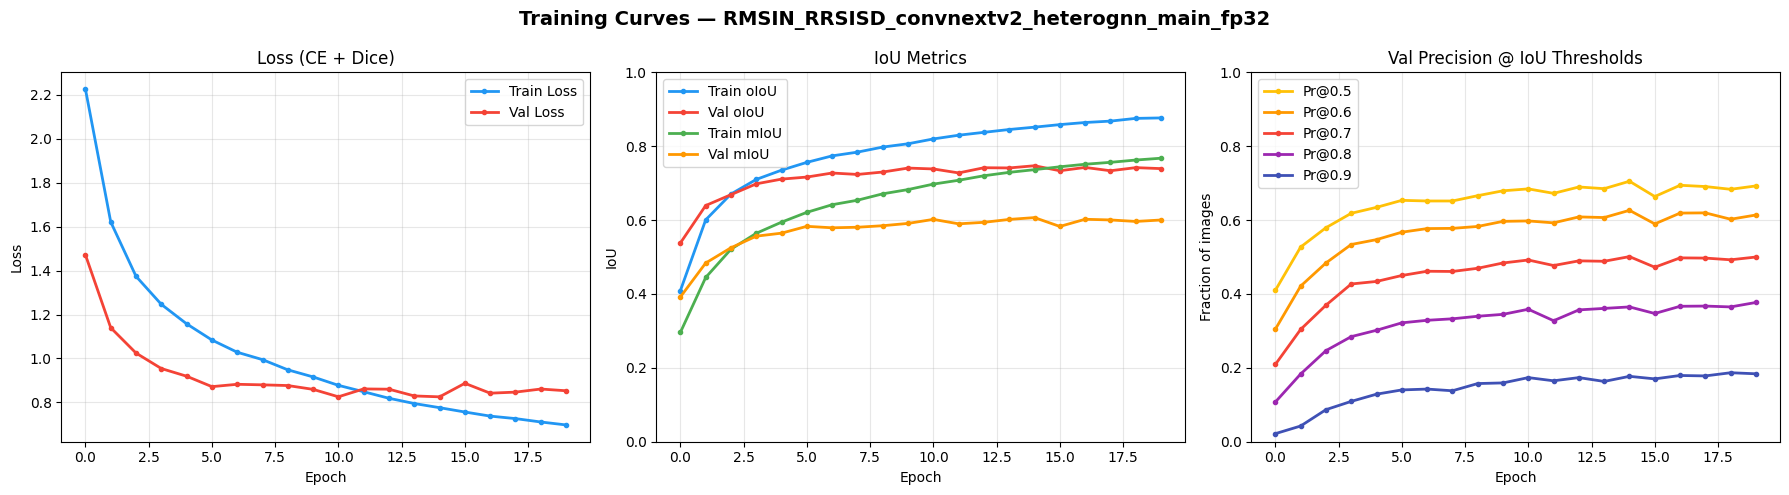

[Logger] Curves  → /content/drive/MyDrive/CSE465/checkpoints/RMSIN_RRSISD_convnextv2_heterognn_main_fp32_training_curves.png


In [ ]:
# ============================================================
# 13j. Main Training Loop (CE + Dice + ARPL — Integrated)
# ============================================================
from tqdm.auto import tqdm

epoch_timer   = EpochTimer()
train_metrics = SegmentationMetrics()
val_metrics   = SegmentationMetrics()
logger = EpochLogger(save_dir=cfg.output_dir, model_id=cfg.model_id)

start_epoch, best_oiou = load_checkpoint_arpl(
    model, arpl_module, optimizer, scheduler, cfg)

gc.collect()
torch.cuda.empty_cache()

patience = getattr(cfg, 'patience', 5)
epochs_no_improve = 0

print(f'\n{"="*60}')
print(f' Training : epoch {start_epoch} → {cfg.epochs - 1}')
print(f' Device   : {DEVICE} ({torch.cuda.get_device_name(0)})')
print(f' Batch    : {cfg.batch_size}')
print(f' Loss     : CE + Dice + ARPL (lambda={ARPL_LAMBDA})')
print(f' ARPL     : {NUM_CATEGORIES} reciprocal points')
print(f' Early stop: patience={patience}')
print(f' Output   : {cfg.output_dir}')
print(f'{"="*60}\n')

t0 = time.time()

epoch_pbar = tqdm(range(start_epoch, cfg.epochs),
                  desc='Overall', unit='epoch',
                  dynamic_ncols=True, leave=True,
                  bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} epochs [{elapsed}<{remaining}]')

for epoch in epoch_pbar:

    train_loss, train_stats = train_one_epoch_arpl(
        model, arpl_module, train_loader_osl, criterion,
        optimizer, scheduler, epoch, cfg,
        metrics=train_metrics, timer=epoch_timer)

    if epoch == start_epoch:
        peak = torch.cuda.max_memory_allocated(0) / 1024**3
        total_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f'\n  [GPU peak memory: {peak:.2f} / {total_mem:.1f} GB]')
        torch.cuda.reset_peak_memory_stats()

    val_loss, val_stats = evaluate(
        model, val_loader, criterion, epoch,
        metrics=val_metrics, timer=epoch_timer)

    is_best = val_stats["oIoU"] * 100 > best_oiou
    if is_best:
        best_oiou = val_stats["oIoU"] * 100
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    save_checkpoint_arpl(model, arpl_module, optimizer, scheduler,
                         epoch, best_oiou, cfg, is_best)

    logger.log(
        epoch,
        train_loss=train_loss,
        val_loss=val_loss,
        train_oIoU=train_stats["oIoU"],
        val_oIoU=val_stats["oIoU"],
        train_mIoU=train_stats["mIoU"],
        val_mIoU=val_stats["mIoU"],
        seg_loss=train_stats.get('seg_loss', 0),
        arpl_loss=train_stats.get('arpl_loss', 0),
        **{f"val_{k}": v for k, v in val_stats.items() if k.startswith("Pr@")},
    )

    print(f'--> Epoch {epoch}/{cfg.epochs-1} | '
          f'Total: {train_loss:.4f} (seg={train_stats.get("seg_loss",0):.4f}, '
          f'arpl={train_stats.get("arpl_loss",0):.4f}) | '
          f'Val oIoU: {val_stats["oIoU"]*100:.2f}% | '
          f'Best: {best_oiou:.2f}% | '
          f'Patience: {epochs_no_improve}/{patience}')

    epoch_pbar.set_postfix(
        val_oIoU=f'{val_stats["oIoU"]*100:.2f}%',
        best=f'{best_oiou:.2f}%')

    gc.collect()
    torch.cuda.empty_cache()

    if epochs_no_improve >= patience:
        print(f'\n  Early stopping — no improvement for {patience} epochs.')
        break

# Clean up feature extractor
feat_extractor.remove()

total_time = time.time() - t0
print(f'\n{"="*60}')
print(f' Training complete!')
print(f' Total time : {datetime.timedelta(seconds=int(total_time))}')
print(f' Best oIoU  : {best_oiou:.2f}%')
print(f' Loss       : CE + Dice + ARPL (integrated)')
print(f'{"="*60}\n')

epoch_timer.summary()
logger.save_json()
logger.plot_curves()

In [ ]:
# ============================================================
# 12. Test Set Evaluation
# ============================================================

@torch.no_grad()
def evaluate_test(model, loader, criterion, cfg, metrics: SegmentationMetrics):
    """Test-set evaluation. Uses the same prediction format as the val
    loop (softmax probs → metrics) so test and val numbers are
    computed via the same code path.
    """
    model.eval()
    metrics.reset()
    total_loss = 0.0
    n_batches  = 0

    pbar = tqdm(loader, desc='Testing', unit='batch',
                dynamic_ncols=True, leave=True,
                bar_format='{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]')

    for imgs, masks, ids, attn in pbar:
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        ids   = ids.to(DEVICE,  non_blocking=True)
        attn  = attn.to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.bfloat16,
                            enabled=getattr(cfg, 'use_bf16', False)):
            out  = model(imgs, ids, attn)
            loss = criterion(out, masks)

        total_loss += loss.item()
        n_batches  += 1

        # Match the val loop exactly: softmax probs → metrics.
        # SegmentationMetrics.update() thresholds at 0.5 internally,
        # so this is equivalent to argmax binary, but keeping the
        # formulation aligned with val removes ambiguity.
        pred_up   = F.interpolate(out, size=masks.shape[-2:],
                                  mode='bilinear', align_corners=False)
        pred_prob = torch.softmax(pred_up, dim=1)[:, 1:, :, :]
        metrics.update(pred_prob, masks)

        pbar.set_postfix(loss=f'{total_loss/n_batches:.4f}')

    test_loss = total_loss / max(n_batches, 1)
    stats     = metrics.compute()
    return test_loss, stats


# ── Load best checkpoint before testing ─────────────────────
best_ckpt_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')
ckpt = None
if os.path.exists(best_ckpt_path):
    ckpt = torch.load(best_ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt['model'], strict=False)
    print(f'Loaded best checkpoint (epoch {ckpt["epoch"]}, '
          f'val oIoU={ckpt["best_oiou"]:.2f}%)')
else:
    print(f'[warn] No best checkpoint at {best_ckpt_path}')
    print(f'       Evaluating with current in-memory model weights.')

# ── Run test evaluation ──────────────────────────────────────
test_metrics = SegmentationMetrics()
test_loss, test_stats = evaluate_test(model, test_loader, criterion, cfg, test_metrics)

# ── Report ───────────────────────────────────────────────────
print(f'\n{"="*60}')
print(f'  TEST SET RESULTS — {getattr(cfg, "ablation_label", "unknown")}')
print(f'{"="*60}')
rows = [
    ['Test Loss',  f'{test_loss:.4f}'],
    ['oIoU',       f'{test_stats["oIoU"]*100:.2f}%'],
    ['mIoU',       f'{test_stats["mIoU"]*100:.2f}%'],
]
for k in SegmentationMetrics.THRESHOLDS:
    rows.append([f'Pr@{k}', f'{test_stats[f"Pr@{k}"]*100:.2f}%'])
print(tabulate(rows, headers=['Metric', 'Value'], tablefmt='rounded_outline'))
print()

# ── Save to JSON, keyed by model_id (no overwrites across ablations) ──
import json
results_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_test_results.json')
results = {
    'model_id'         : cfg.model_id,
    'ablation_label'   : getattr(cfg, 'ablation_label', 'unknown'),
    'fusion_type'      : cfg.fusion_type,
    'gnn_rounds'       : getattr(cfg, 'gnn_rounds', None),
    'gnn_vv_max_tokens': getattr(cfg, 'gnn_vv_max_tokens', None),
    'gnn_vv_strided'   : getattr(cfg, 'gnn_vv_strided', None),
    'best_epoch'       : ckpt['epoch'] if ckpt else None,
    'best_val_oiou'    : ckpt['best_oiou'] if ckpt else None,
    'test_loss'        : test_loss,
    'oIoU'             : test_stats['oIoU'],
    'mIoU'             : test_stats['mIoU'],
    **{f'Pr@{k}': test_stats[f'Pr@{k}'] for k in SegmentationMetrics.THRESHOLDS},
    'checkpoint'       : best_ckpt_path,
}
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)
print(f'Results saved → {results_path}')

Loaded best checkpoint (epoch 14, val oIoU=74.71%)


Testing:   0%|          | 0/871 [00:00<?, ?batch/s]


  TEST SET RESULTS — main
╭───────────┬─────────╮
│ Metric    │ Value   │
├───────────┼─────────┤
│ Test Loss │ 0.2014  │
│ oIoU      │ 73.42%  │
│ mIoU      │ 60.19%  │
│ Pr@0.5    │ 69.35%  │
│ Pr@0.6    │ 61.33%  │
│ Pr@0.7    │ 49.61%  │
│ Pr@0.8    │ 35.91%  │
│ Pr@0.9    │ 18.01%  │
╰───────────┴─────────╯

Results saved → /content/drive/MyDrive/CSE465/checkpoints/RMSIN_RRSISD_convnextv2_heterognn_main_fp32_test_results.json


In [ ]:
# ============================================================
# 13k. Rejection Scorers — 5 scorers from single inference pass
# ============================================================

from sklearn.metrics import roc_auc_score, roc_curve

def compute_all_scores(seg_logits, fused_features, arpl_mod,
                       prototypes, temp=1.0):
    logits_pooled = seg_logits.mean(dim=[2, 3])
    probs = F.softmax(logits_pooled, dim=1)
    msp = -probs.max(dim=1).values
    maxlogit = -logits_pooled.max(dim=1).values
    energy = -temp * torch.logsumexp(logits_pooled / temp, dim=1)

    if len(prototypes) > 0:
        proto_stack = torch.stack(list(prototypes.values())).to(fused_features.device)
        dists = torch.cdist(fused_features.unsqueeze(0),
                           proto_stack.unsqueeze(0)).squeeze(0)
        proto_dist = dists.min(dim=1).values
    else:
        proto_dist = torch.zeros(seg_logits.size(0), device=seg_logits.device)

    arpl_score = arpl_mod.compute_arpl_score(fused_features)

    return {
        'MSP': msp, 'MaxLogit': maxlogit, 'Energy': energy,
        'ProtoDist': proto_dist, 'ARPL': arpl_score,
    }

def compute_oscr(seen_scores, unknown_scores):
    all_scores = np.concatenate([seen_scores, unknown_scores])
    thresholds = np.sort(np.unique(all_scores))
    ccrs = [(seen_scores <= t).mean() for t in thresholds]
    fprs = [(unknown_scores <= t).mean() for t in thresholds]
    ccrs, fprs = np.array(ccrs), np.array(fprs)
    si = np.argsort(fprs)
    return {'auc': np.trapz(ccrs[si], fprs[si])}

print('5 rejection scorers + OSCR defined.')

5 rejection scorers + OSCR defined.


In [ ]:
# ============================================================
# 13l. OSL Evaluation — loads from checkpoint, no re-training
# ============================================================

def evaluate_osl_full(model, arpl_mod, split_info, cfg):
    """Evaluate OSL on one split using the trained model."""
    known_ds = OSLRRSISDDataset(
        cfg, split='val', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']))
    unknown_ds = OSLRRSISDDataset(
        cfg, split='val', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['unknown_ids']))

    if len(known_ds) == 0 or len(unknown_ds) == 0:
        print(f'  ⚠ Insufficient data'); return None

    bs = min(cfg.batch_size, 8)
    known_loader = DataLoader(known_ds, batch_size=bs, shuffle=False,
                              num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
    unknown_loader = DataLoader(unknown_ds, batch_size=bs, shuffle=False,
                                num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

    # Build prototypes from training data
    proto_ds = OSLRRSISDDataset(
        cfg, split='train', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']))
    proto_loader = DataLoader(proto_ds, batch_size=bs, shuffle=False,
                              num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

    model.eval()
    arpl_mod.eval()
    feat_dim = model.backbone.hidden_sizes[-1]

    # Build prototypes
    proto_sum = defaultdict(lambda: torch.zeros(feat_dim))
    proto_cnt = defaultdict(int)
    ext = FeatureExtractor(model)
    for imgs, masks, ids, attn, cats in tqdm(proto_loader, desc='  Prototypes', leave=False):
        imgs = imgs.to(DEVICE); ids = ids.to(DEVICE); attn = attn.to(DEVICE)
        with torch.no_grad(): _ = model(imgs, ids, attn)
        feats = ext.get()
        for j, c in enumerate(cats):
            proto_sum[int(c)] += feats[j].cpu()
            proto_cnt[int(c)] += 1
    ext.remove()
    prototypes = {c: proto_sum[c] / proto_cnt[c] for c in proto_sum if proto_cnt[c] > 0}
    print(f'  Built {len(prototypes)} prototypes')

    scorers = ['MSP', 'MaxLogit', 'Energy', 'ProtoDist', 'ARPL']

    def _score(loader, label):
        ext2 = FeatureExtractor(model)
        all_scores = {s: [] for s in scorers}
        for imgs, masks, ids, attn, _ in tqdm(loader, desc=f'    {label}', leave=False):
            imgs = imgs.to(DEVICE); ids = ids.to(DEVICE); attn = attn.to(DEVICE)
            with torch.no_grad(): logits = model(imgs, ids, attn)
            feats = ext2.get()
            scores = compute_all_scores(logits, feats, arpl_mod, prototypes)
            for s in scorers:
                all_scores[s].extend(scores[s].cpu().tolist())
        ext2.remove()
        return {s: np.array(v) for s, v in all_scores.items()}

    known_scores = _score(known_loader, 'known')
    unknown_scores = _score(unknown_loader, 'unknown')

    # Segmentation on known
    seg_metrics = SegmentationMetrics()
    for imgs, masks, ids, attn, _ in known_loader:
        imgs = imgs.to(DEVICE); masks = masks.to(DEVICE)
        ids = ids.to(DEVICE); attn = attn.to(DEVICE)
        with torch.no_grad(): out = model(imgs, ids, attn)
        pred_up = F.interpolate(out, masks.shape[-2:], mode='bilinear', align_corners=False)
        seg_metrics.update(torch.softmax(pred_up, dim=1)[:, 1:], masks)
    seg_stats = seg_metrics.compute()
    seen_miou = seg_stats['mIoU']

    results = {'seen_mIoU': float(seen_miou), 'seen_oIoU': float(seg_stats['oIoU'])}

    for scorer in scorers:
        s_k, s_u = known_scores[scorer], unknown_scores[scorer]
        labels = np.concatenate([np.zeros(len(s_k)), np.ones(len(s_u))])
        scores_all = np.concatenate([s_k, s_u])
        try: auroc = roc_auc_score(labels, scores_all)
        except: auroc = 0.5
        fpr, tpr, _ = roc_curve(labels, scores_all)
        idx95 = np.argmin(np.abs(tpr - 0.95))
        fpr95 = fpr[idx95]
        rej = 1.0 - fpr95
        harmonic = 2 * seen_miou * rej / (seen_miou + rej) if (seen_miou + rej) > 0 else 0.0
        oscr = compute_oscr(s_k, s_u)
        results[scorer] = {
            'auroc': float(auroc), 'fpr_at_95': float(fpr95),
            'harmonic': float(harmonic), 'oscr_auc': float(oscr['auc']),
        }
        print(f'    {scorer:>10s}: AUROC={auroc:.4f}  FPR@95={fpr95:.4f}  '
              f'Harmonic={harmonic:.4f}  OSCR={oscr["auc"]:.4f}')

    print(f'    Seen mIoU={seen_miou*100:.2f}%, oIoU={seg_stats["oIoU"]*100:.2f}%')
    return results

print('evaluate_osl_full() defined — uses checkpoint, no re-training.')

evaluate_osl_full() defined — uses checkpoint, no re-training.


In [ ]:
# ============================================================
# 13m. Run OSL Evaluation (from best checkpoint)
# ============================================================

print(f'\n{"="*70}')
print(f' OSL Evaluation from Checkpoint')
print(f' Splits: {len(osl_splits)}, Model: {cfg.model_id}')
print(f'{"="*70}\n')

# Load best checkpoint (model + ARPL)
best_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_best.pth')
if os.path.exists(best_path):
    ckpt = torch.load(best_path, map_location=DEVICE)
    model.load_state_dict(ckpt['model'], strict=False)
    if 'arpl' in ckpt:
        arpl_module.load_state_dict(ckpt['arpl'])
        print(f'✓ Loaded model + ARPL from best checkpoint (epoch {ckpt["epoch"]})')
    else:
        print(f'✓ Loaded model (no ARPL state in checkpoint)')
else:
    print(f'⚠ No best checkpoint at {best_path}, using current weights')

model.eval()
arpl_module.eval()

all_split_results = []

for split_idx, split_info in enumerate(osl_splits):
    print(f'\n{"━"*70}')
    print(f'SPLIT {split_idx}/{len(osl_splits)-1}')
    print(f'  Known({len(split_info["known_cats"])}):   {split_info["known_cats"][:5]}...')
    print(f'  Unknown({len(split_info["unknown_cats"])}): {split_info["unknown_cats"]}')
    print(f'{"━"*70}')

    result = evaluate_osl_full(model, arpl_module, split_info, cfg)

    if result is not None:
        result['split_idx'] = split_idx
        result['known_cats'] = split_info['known_cats']
        result['unknown_cats'] = split_info['unknown_cats']
        all_split_results.append(result)

print(f'\nCompleted {len(all_split_results)}/{len(osl_splits)} splits.')


 OSL Evaluation from Checkpoint
 Splits: 3, Model: RMSIN_RRSISD_convnextv2_heterognn_main_fp32

✓ Loaded model + ARPL from best checkpoint (epoch 14)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
SPLIT 0/2
  Known(15):   ['Expressway-Service-area', 'Expressway-toll-station', 'airplane', 'airport', 'baseballfield']...
  Unknown(5): ['vehicle', 'chimney', 'storagetank', 'stadium', 'harbor']
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
[OSL val/known] 1261 samples
[OSL val/known] 479 samples
[OSL train/known] 9045 samples


  Prototypes:   0%|          | 0/1131 [00:00<?, ?it/s]

  Built 15 prototypes


    known:   0%|          | 0/158 [00:00<?, ?it/s]

    unknown:   0%|          | 0/60 [00:00<?, ?it/s]

...

  Prototypes:   0%|          | 0/1109 [00:00<?, ?it/s]

  Built 15 prototypes


    known:   0%|          | 0/156 [00:00<?, ?it/s]

    unknown:   0%|          | 0/62 [00:00<?, ?it/s]

           MSP: AUROC=0.3267  FPR@95=0.9936  Harmonic=0.0127  OSCR=0.3267
      MaxLogit: AUROC=0.3287  FPR@95=0.9535  Harmonic=0.0868  OSCR=0.3287
        Energy: AUROC=0.3287  FPR@95=0.9535  Harmonic=0.0868  OSCR=0.3287
     ProtoDist: AUROC=0.6567  FPR@95=0.8355  Harmonic=0.2616  OSCR=0.6567
          ARPL: AUROC=0.3312  FPR@95=0.9992  Harmonic=0.0016  OSCR=0.3313
    Seen mIoU=63.80%, oIoU=74.50%

Completed 3/3 splits.


In [ ]:
# ============================================================
# 13n. Aggregate ARPL + OSL Results
# ============================================================

if len(all_split_results) == 0:
    print('No results to aggregate.')
else:
    scorers = ['MSP', 'MaxLogit', 'Energy', 'ProtoDist', 'ARPL']

    print(f'\n{"="*70}')
    print(f' ARPL OSL Results — Averaged over {len(all_split_results)} splits')
    print(f'{"="*70}')

    mious = [r['seen_mIoU'] for r in all_split_results]
    oious = [r['seen_oIoU'] for r in all_split_results]
    print(f'\n  SEEN-CLASS SEGMENTATION:')
    print(f'    mIoU : {np.mean(mious)*100:.2f}% ± {np.std(mious)*100:.2f}%')
    print(f'    oIoU : {np.mean(oious)*100:.2f}% ± {np.std(oious)*100:.2f}%')

    rows = []
    for s in scorers:
        aurocs    = [r[s]['auroc'] for r in all_split_results]
        fpr95s    = [r[s]['fpr_at_95'] for r in all_split_results]
        harmonics = [r[s]['harmonic'] for r in all_split_results]
        oscrs     = [r[s]['oscr_auc'] for r in all_split_results]
        rows.append([s,
            f'{np.mean(aurocs):.4f} ± {np.std(aurocs):.4f}',
            f'{np.mean(fpr95s):.4f} ± {np.std(fpr95s):.4f}',
            f'{np.mean(harmonics):.4f} ± {np.std(harmonics):.4f}',
            f'{np.mean(oscrs):.4f} ± {np.std(oscrs):.4f}',
        ])
    print(f'\n  REJECTION SCORER COMPARISON:')
    print(tabulate(rows,
                   headers=['Scorer', 'AUROC ↑', 'FPR@95 ↓', 'Harmonic ↑', 'OSCR AUC ↑'],
                   tablefmt='rounded_outline'))

    split_rows = []
    for r in all_split_results:
        split_rows.append([r['split_idx'],
            f'{r["seen_mIoU"]*100:.2f}%', f'{r["ARPL"]["auroc"]:.4f}',
            f'{r["Energy"]["auroc"]:.4f}', f'{r["MSP"]["auroc"]:.4f}',
            f'{r["ARPL"]["harmonic"]:.4f}',
            ', '.join(r['unknown_cats'][:3]),
        ])
    print(f'\n  PER-SPLIT BREAKDOWN:')
    print(tabulate(split_rows,
                   headers=['Split', 'Seen mIoU', 'ARPL AUROC', 'Energy AUROC',
                            'MSP AUROC', 'ARPL Harmonic', 'Unknown cats'],
                   tablefmt='rounded_outline'))

    save_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_arpl_osl_results.json')
    save_data = {
        'config': {'arpl_lambda': ARPL_LAMBDA, 'arpl_margin': ARPL_MARGIN,
                   'num_splits': len(all_split_results)},
        'aggregate': {
            'seen_mIoU_mean': float(np.mean(mious)),
            'arpl_auroc_mean': float(np.mean([r['ARPL']['auroc'] for r in all_split_results])),
        },
        'per_split': all_split_results,
    }
    with open(save_path, 'w') as f:
        json.dump(save_data, f, indent=2, default=str)
    print(f'\nResults saved → {save_path}')


 ARPL OSL Results — Averaged over 3 splits

  SEEN-CLASS SEGMENTATION:
    mIoU : 64.28% ± 1.18%
    oIoU : 74.34% ± 0.38%

  REJECTION SCORER COMPARISON:
╭───────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────╮
│ Scorer    │ AUROC ↑         │ FPR@95 ↓        │ Harmonic ↑      │ OSCR AUC ↑      │
├───────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┤
│ MSP       │ 0.2834 ± 0.0655 │ 0.9957 ± 0.0030 │ 0.0084 ± 0.0060 │ 0.2833 ± 0.0655 │
│ MaxLogit  │ 0.2946 ± 0.0696 │ 0.9649 ± 0.0199 │ 0.0654 ± 0.0365 │ 0.2946 ± 0.0696 │
│ Energy    │ 0.2946 ± 0.0696 │ 0.9649 ± 0.0199 │ 0.0654 ± 0.0365 │ 0.2946 ± 0.0696 │
│ ProtoDist │ 0.7034 ± 0.0354 │ 0.7811 ± 0.0385 │ 0.3246 ± 0.0446 │ 0.7033 ± 0.0354 │
│ ARPL      │ 0.3249 ± 0.0445 │ 0.9980 ± 0.0017 │ 0.0040 ± 0.0034 │ 0.3249 ± 0.0445 │
╰───────────┴─────────────────┴─────────────────┴─────────────────┴─────────────────╯

  PER-SPLIT BREAKDOWN:
╭─────────┬─────────────┬──────────────┬──────

Visualizing split 0 using trained checkpoint (no re-training)...
[OSL val/known] 200 samples
[OSL val/known] 200 samples
[OSL train/known] 500 samples


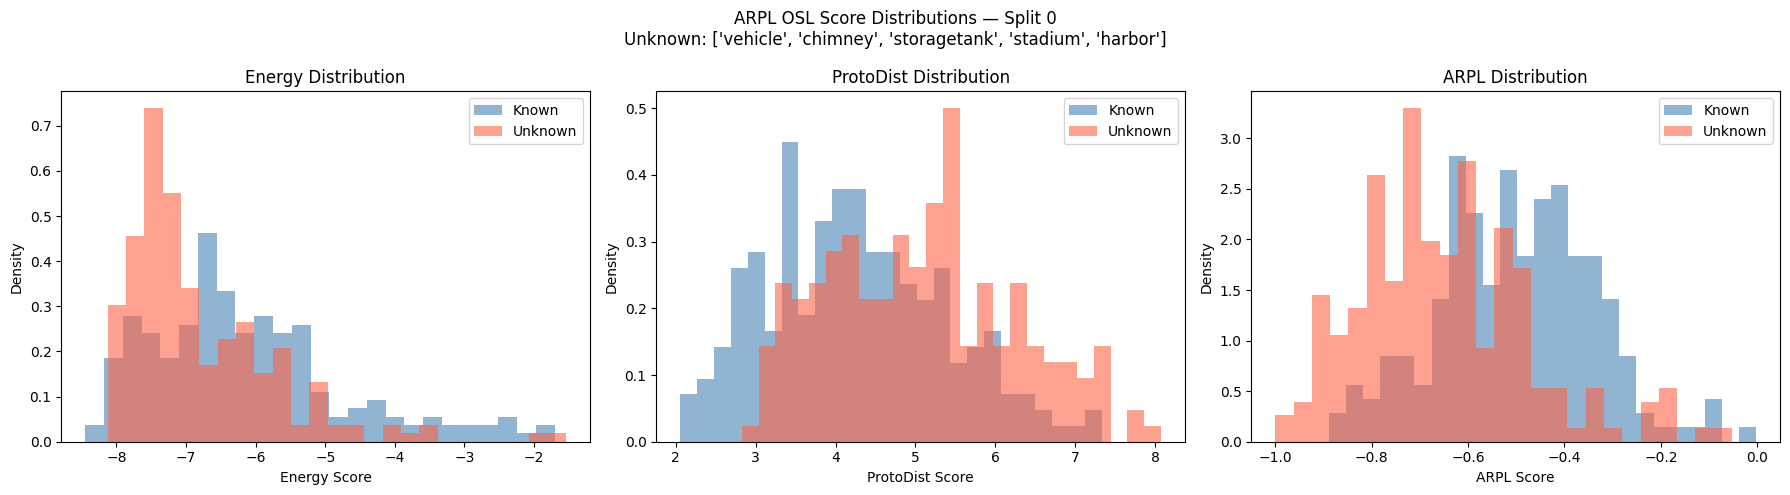

✓ Distribution plot saved (from checkpoint, no re-training).


In [ ]:
# ============================================================
# 13o. Score Distribution Visualization (from checkpoint — no re-training!)
# ============================================================

if len(all_split_results) > 0:
    split_info = osl_splits[0]
    print(f'Visualizing split 0 using trained checkpoint (no re-training)...')

    # Model is already loaded from checkpoint in cell 56
    model.eval()
    arpl_module.eval()

    known_ds = OSLRRSISDDataset(
        cfg, split='val', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']), max_samples=200)
    unknown_ds = OSLRRSISDDataset(
        cfg, split='val', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['unknown_ids']), max_samples=200)

    bs = min(8, cfg.batch_size)
    kl = DataLoader(known_ds, batch_size=bs, shuffle=False,
                    num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
    ul = DataLoader(unknown_ds, batch_size=bs, shuffle=False,
                    num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

    # Build prototypes
    proto_ds = OSLRRSISDDataset(
        cfg, split='train', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']), max_samples=500)
    pl = DataLoader(proto_ds, batch_size=bs, shuffle=False,
                    num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

    feat_dim = model.backbone.hidden_sizes[-1]
    psum = defaultdict(lambda: torch.zeros(feat_dim))
    pcnt = defaultdict(int)
    ext = FeatureExtractor(model)
    for imgs, _, ids, attn, cats in pl:
        imgs=imgs.to(DEVICE); ids=ids.to(DEVICE); attn=attn.to(DEVICE)
        with torch.no_grad(): _ = model(imgs, ids, attn)
        f = ext.get()
        for j, c in enumerate(cats):
            psum[int(c)] += f[j].cpu(); pcnt[int(c)] += 1
    ext.remove()
    protos = {c: psum[c]/pcnt[c] for c in psum if pcnt[c]>0}

    def _collect(loader):
        e = FeatureExtractor(model)
        r = {s: [] for s in ['Energy', 'ProtoDist', 'ARPL']}
        for imgs, _, ids, attn, _ in loader:
            imgs=imgs.to(DEVICE); ids=ids.to(DEVICE); attn=attn.to(DEVICE)
            with torch.no_grad(): logits = model(imgs, ids, attn)
            feats = e.get()
            sc = compute_all_scores(logits, feats, arpl_module, protos)
            for s in r: r[s].extend(sc[s].cpu().tolist())
        e.remove()
        return {s: np.array(v) for s, v in r.items()}

    k_sc = _collect(kl)
    u_sc = _collect(ul)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, name in zip(axes, ['Energy', 'ProtoDist', 'ARPL']):
        ax.hist(k_sc[name], bins=25, alpha=0.6, label='Known', color='steelblue', density=True)
        ax.hist(u_sc[name], bins=25, alpha=0.6, label='Unknown', color='tomato', density=True)
        ax.set_xlabel(name + ' Score')
        ax.set_ylabel('Density')
        ax.set_title(f'{name} Distribution')
        ax.legend()

    plt.suptitle(f'ARPL OSL Score Distributions — Split 0\n'
                 f'Unknown: {split_info["unknown_cats"]}', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.output_dir, f'{cfg.model_id}_arpl_osl_dist.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print('✓ Distribution plot saved (from checkpoint, no re-training).')
else:
    print('No results for visualization.')


Generating OSL inference visualization...
[OSL train/known] 500 samples
[OSL test/known] 12 samples
[OSL test/known] 12 samples


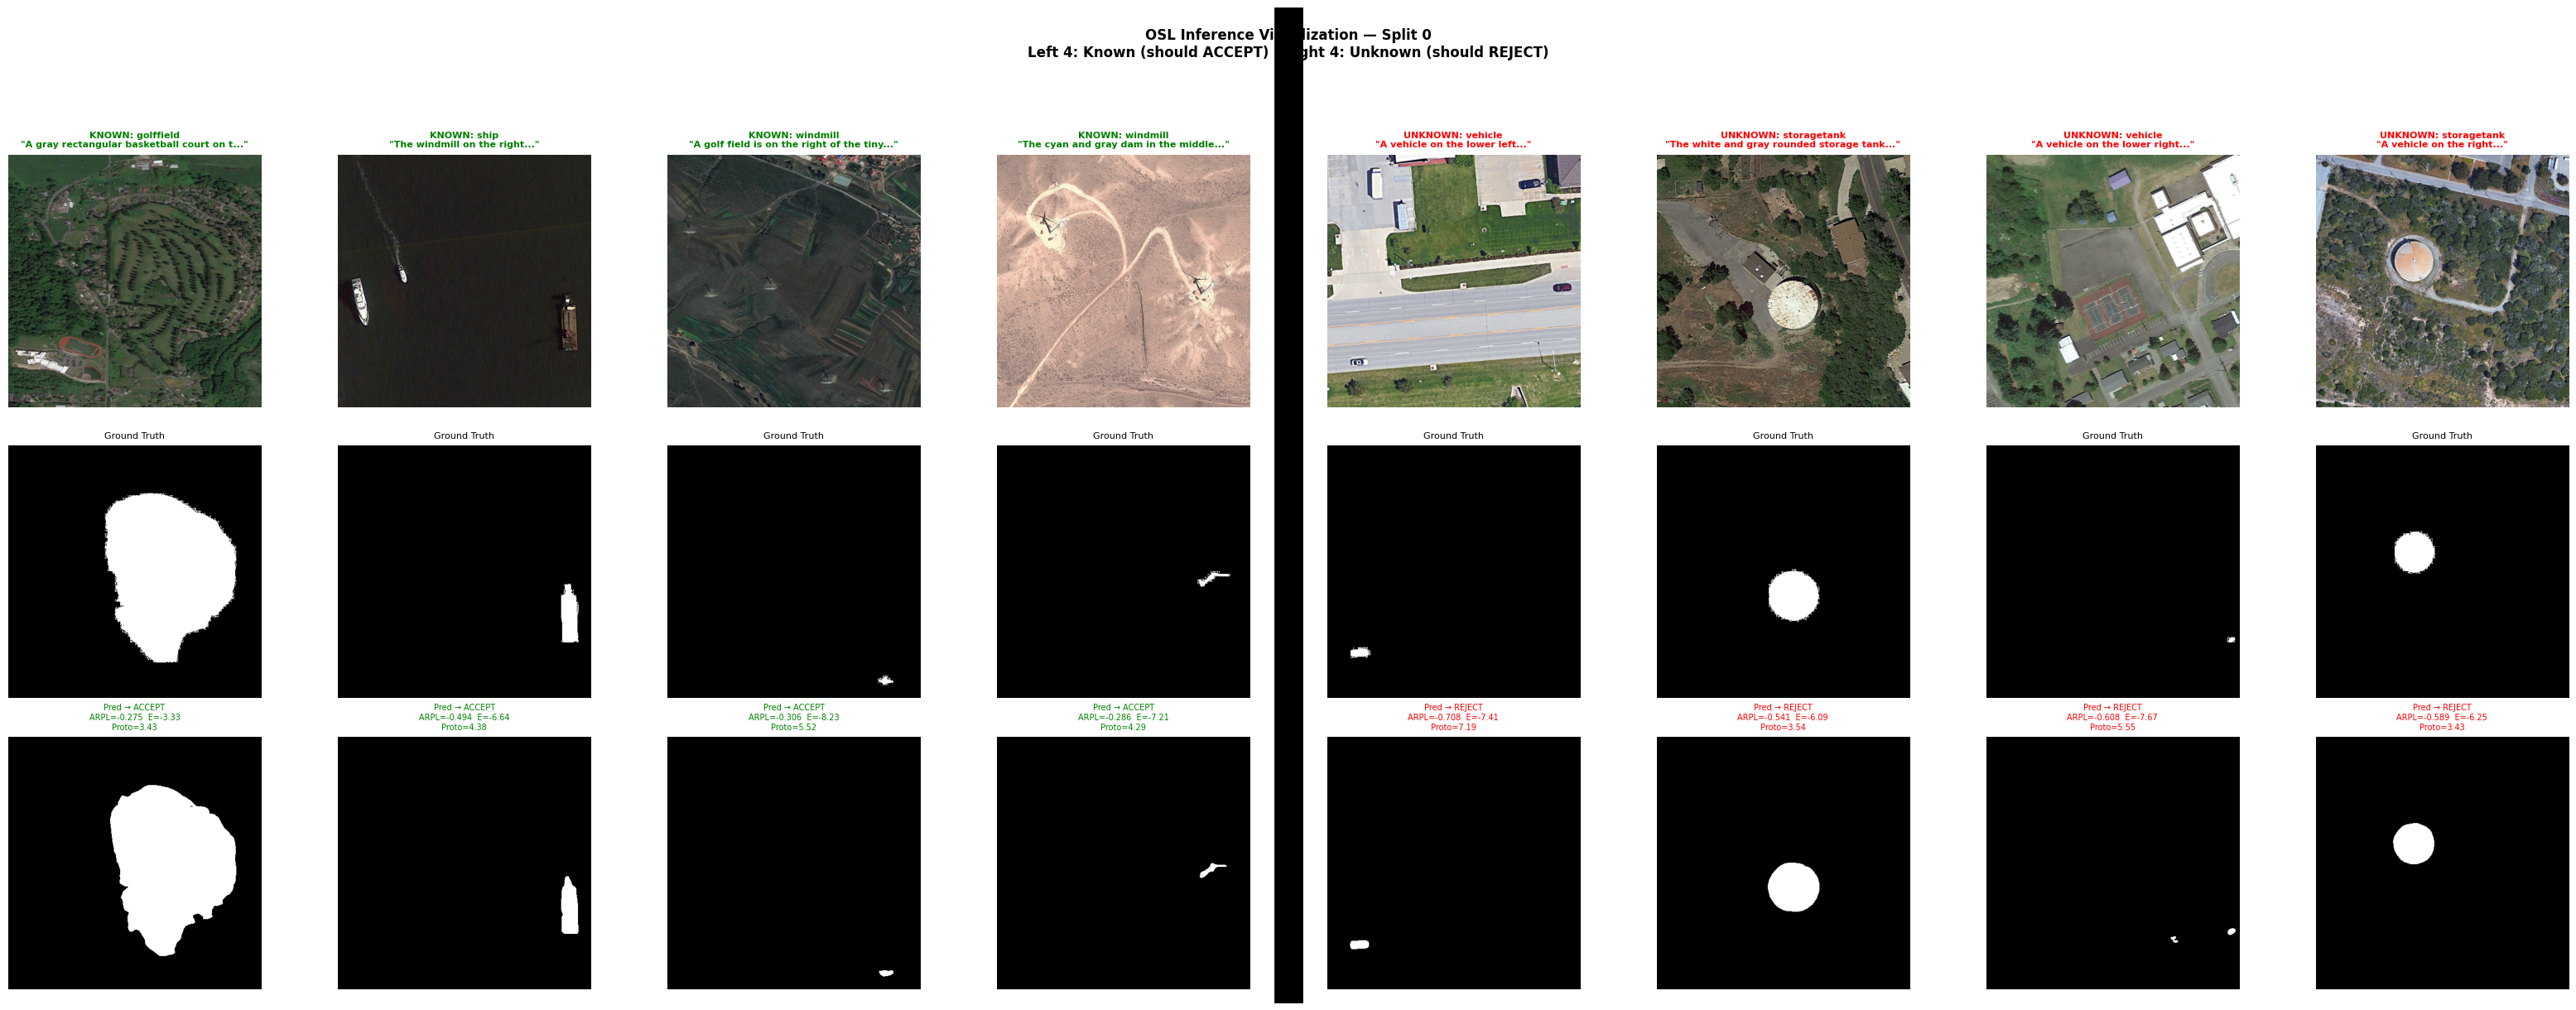

✓ Inference visualization saved → /content/drive/MyDrive/CSE465/checkpoints/RMSIN_RRSISD_convnextv2_heterognn_main_fp32_osl_inference_viz.png


In [ ]:
# ============================================================
# 13p. OSL Inference Visualization — Known vs Unknown on Test Data
# ============================================================

from transformers import BertTokenizer

def visualize_osl_inference(model, arpl_mod, split_info, cfg,
                            num_known=4, num_unknown=4):
    """
    Visualize OSL inference on test data:
    - Shows image + text description + predicted mask + OSL decision
    - Top row: Known class samples (should be ACCEPTED)
    - Bottom row: Unknown class samples (should be REJECTED)
    """
    model.eval()
    arpl_mod.eval()

    # Build prototypes from training set
    proto_ds = OSLRRSISDDataset(
        cfg, split='train', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']), max_samples=500)
    proto_loader = DataLoader(proto_ds, batch_size=8, shuffle=False,
                              num_workers=2, pin_memory=False)

    feat_dim = model.backbone.hidden_sizes[-1]
    psum = defaultdict(lambda: torch.zeros(feat_dim))
    pcnt = defaultdict(int)
    ext = FeatureExtractor(model)
    for imgs, _, ids, attn, cats in proto_loader:
        imgs=imgs.to(DEVICE); ids=ids.to(DEVICE); attn=attn.to(DEVICE)
        with torch.no_grad(): _ = model(imgs, ids, attn)
        feats = ext.get()
        for j, c in enumerate(cats):
            psum[int(c)] += feats[j].cpu(); pcnt[int(c)] += 1
    ext.remove()
    prototypes = {c: psum[c]/pcnt[c] for c in psum if pcnt[c]>0}

    # Load test samples for known and unknown categories
    known_test = OSLRRSISDDataset(
        cfg, split='test', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['known_ids']), max_samples=num_known * 3)
    unknown_test = OSLRRSISDDataset(
        cfg, split='test', transform=get_transform('val', cfg.img_size),
        category_ids=set(split_info['unknown_ids']), max_samples=num_unknown * 3)

    # Denormalization for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def get_samples_with_scores(dataset, n):
        loader = DataLoader(dataset, batch_size=1, shuffle=True, num_workers=0)
        results = []
        ext2 = FeatureExtractor(model)
        for imgs, masks, ids, attn, cat_ids in loader:
            if len(results) >= n:
                break
            imgs_dev = imgs.to(DEVICE); ids_dev = ids.to(DEVICE)
            attn_dev = attn.to(DEVICE)

            with torch.no_grad():
                logits = model(imgs_dev, ids_dev, attn_dev)
            feats = ext2.get()

            # Get scores
            scores = compute_all_scores(logits, feats, arpl_mod, prototypes)
            arpl_score = scores['ARPL'].item()
            energy_score = scores['Energy'].item()
            proto_score = scores['ProtoDist'].item()

            # Get predicted mask
            pred_up = F.interpolate(logits, masks.shape[-2:],
                                    mode='bilinear', align_corners=False)
            pred_mask = torch.argmax(pred_up, dim=1).squeeze().cpu().numpy()

            # Denormalize image
            img_disp = (imgs[0] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

            # Get text description
            idx_in_ds = loader.dataset.samples[len(results)]
            text_desc = idx_in_ds['sent']
            cat_id = int(cat_ids[0])
            cat_name = cat_id_to_name.get(cat_id, f'ID:{cat_id}')

            results.append({
                'image': img_disp,
                'mask_gt': masks[0].squeeze().numpy(),
                'mask_pred': pred_mask,
                'text': text_desc,
                'cat_name': cat_name,
                'arpl_score': arpl_score,
                'energy_score': energy_score,
                'proto_score': proto_score,
            })
        ext2.remove()
        return results

    known_samples = get_samples_with_scores(known_test, num_known)
    unknown_samples = get_samples_with_scores(unknown_test, num_unknown)

    # Plot
    total = num_known + num_unknown
    fig, axes = plt.subplots(3, total, figsize=(4 * total, 12))

    for col, sample in enumerate(known_samples + unknown_samples):
        is_known = col < num_known
        label = 'KNOWN' if is_known else 'UNKNOWN'
        color = 'green' if is_known else 'red'

        # Row 0: Image with text
        axes[0, col].imshow(sample['image'])
        axes[0, col].set_title(
            f'{label}: {sample["cat_name"]}\n"{sample["text"][:40]}..."',
            fontsize=8, color=color, fontweight='bold')
        axes[0, col].axis('off')

        # Row 1: GT mask
        axes[1, col].imshow(sample['mask_gt'], cmap='gray', vmin=0, vmax=1)
        axes[1, col].set_title('Ground Truth', fontsize=8)
        axes[1, col].axis('off')

        # Row 2: Predicted mask + scores
        axes[2, col].imshow(sample['mask_pred'], cmap='gray', vmin=0, vmax=1)
        decision = 'ACCEPT' if is_known else 'REJECT'
        axes[2, col].set_title(
            f'Pred → {decision}\n'
            f'ARPL={sample["arpl_score"]:.3f}  E={sample["energy_score"]:.2f}\n'
            f'Proto={sample["proto_score"]:.2f}',
            fontsize=7, color=color)
        axes[2, col].axis('off')

    # Add row labels
    axes[0, 0].set_ylabel('Image + Text', fontsize=10, fontweight='bold')
    axes[1, 0].set_ylabel('Ground Truth', fontsize=10, fontweight='bold')
    axes[2, 0].set_ylabel('Prediction + Scores', fontsize=10, fontweight='bold')

    # Add separator line
    fig.patches.append(plt.Rectangle(
        (num_known / total - 0.005, 0), 0.01, 1,
        transform=fig.transFigure, color='black', linewidth=2))

    plt.suptitle(
        f'OSL Inference Visualization — Split 0\n'
        f'Left {num_known}: Known (should ACCEPT) | '
        f'Right {num_unknown}: Unknown (should REJECT)',
        fontsize=12, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    save_path = os.path.join(cfg.output_dir, f'{cfg.model_id}_osl_inference_viz.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'✓ Inference visualization saved → {save_path}')


# ── Run visualization ──
if len(all_split_results) > 0:
    print(f'\nGenerating OSL inference visualization...')
    visualize_osl_inference(model, arpl_module, osl_splits[0], cfg,
                            num_known=4, num_unknown=4)
else:
    print('No OSL results — skipping inference visualization.')